# Nutritional Analysis and Personalised Dietary Recommendation System

## Section 1: Project Introduction

This project develops an end-to-end artificial intelligence system for analysing meal photographs and generating personalised dietary recommendations. It addresses limitations of traditional dietary assessment, including recall bias, under-reporting and participant burden, by automating food identification and nutritional evaluation. The system compares U-Net with a ResNet-34 encoder and DeepLabV3+ with a ResNet-50 encoder for segmenting food items. FoodSeg103, comprising 7,118 images across 103 food categories, supports model development and evaluation. Segmented food labels are aligned with USDA FNDDS 2021–2023, enabling nutrient information, confidence-scored matching and manual verification. Portion-adjusted energy and macronutrients are calculated using standard serving weights and user-entered quantities. Finally, Mifflin–St Jeor and WHO BMI standards inform rule-based recommendations. The notebook covers data preparation, training, evaluation, integration, visualisation and export.

## Section 2: Environment Setup and Installation

This section prepares the Google Colab Python runtime. We install the required scientific and computer vision packages, including `segmentation-models-pytorch` for pretrained deep learning backbones, `albumentations` for synchronized spatial image augmentations, `datasets` and `pyarrow` for Parquet handling, and `scikit-learn` for similarity matching.

In [ ]:
# Install required packages for Google Colab execution
# !pip install -q opencv-python-headless segmentation-models-pytorch albumentations pyarrow datasets scikit-learn seaborn

In [ ]:
# Ensure all required computer vision and deep learning packages are installed
import sys
import subprocess

required_dependencies = {
    'cv2': 'opencv-python-headless',
    'albumentations': 'albumentations',
    'segmentation_models_pytorch': 'segmentation-models-pytorch',
    'torch': 'torch',
    'torchvision': 'torchvision',
    'pyarrow': 'pyarrow',
    'datasets': 'datasets',
    'sklearn': 'scikit-learn',
    'seaborn': 'seaborn'
}

for module_name, pip_package in required_dependencies.items():
    try:
        __import__(module_name)
    except ImportError:
        print(f"Installing missing package '{pip_package}'...")
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pip_package])

# Core standard libraries
import os
import gc
import io
import time
import json
import zipfile
import urllib.request
from pathlib import Path
from difflib import SequenceMatcher

# Numerical and data manipulation libraries
import numpy as np
import pandas as pd
from PIL import Image

# Computer vision and augmentation
import cv2
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Machine learning and evaluation
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# PyTorch deep learning framework
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision
import segmentation_models_pytorch as smp

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Verify hardware environment
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"PyTorch Version: {torch.__version__}")
print(f"Compute Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Hardware: {torch.cuda.get_device_name(0)}")
    print(f"Available VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
    torch.backends.cudnn.benchmark = True
else:
    print("Notice: CUDA is unavailable. Running on CPU runtime.")

Installing missing package 'segmentation-models-pytorch'...
PyTorch Version: 2.11.0+cu130
Compute Device: cuda
GPU Hardware: Tesla T4
Available VRAM: 14.56 GB


## Section 3: Configuration and Reproducibility

Scientific reproducibility is enforced through deterministic random seeds across PyTorch, NumPy, and standard libraries. All runtime parameters, directory paths, hyperparameter specifications, and execution flags are maintained within a centralized configuration dictionary.

In [ ]:
# Resolve dataset directory across standard local and Google Colab environments
def resolve_dataset_paths():
    """Automatically locate dataset paths across local, Colab root, and Google Drive directories."""
    candidate_dirs = [
        './Data',
        '../Data',
        '/content/Data',
        '/content/drive/MyDrive/Data',
        '/content/drive/MyDrive',
        os.path.join(os.getcwd(), 'Data')
    ]
    resolved_base = './Data'
    for candidate in candidate_dirs:
        if os.path.exists(candidate):
            has_foodseg = os.path.exists(os.path.join(candidate, 'FoodSeg103'))
            has_usda = os.path.exists(os.path.join(candidate, 'FoodData_Central_survey_food'))
            if has_foodseg or has_usda:
                resolved_base = candidate
                break
    return resolved_base, os.path.join(resolved_base, 'FoodSeg103'), os.path.join(resolved_base, 'FoodData_Central_survey_food')

resolved_base, resolved_foodseg, resolved_usda = resolve_dataset_paths()

# Centralized experiment configuration dictionary
CONFIG = {
    # Reproducibility seed
    'seed': 42,

    # Dataset and storage paths (configurable for local execution, Colab local, or Google Drive)
    'data_dir': resolved_base,
    'foodseg_parquet_dir': resolved_foodseg,
    'usda_csv_dir': resolved_usda,
    'output_dir': './outputs',
    'checkpoint_dir': './outputs/checkpoints',
    'figures_dir': './outputs/figures',
    'export_dir': './outputs/exports',

    # Model architecture and image dimensions
    'image_height': 512,
    'image_width': 512,
    'num_classes': 104,  # 0: background + 103 food ingredient categories
    'ignore_index': 255,

    # Training hyperparameters
    'batch_size': 8 if torch.cuda.is_available() else 4,
    'learning_rate': 1e-4,
    'weight_decay': 1e-4,
    'num_epochs': 10,
    'patience': 3,
    'num_workers': 2 if os.name != 'nt' else 0,

    # Execution mode: set quick_test to True for fast pipeline verification with a subset
    'quick_test': False,
    'quick_test_samples': 100,

    # Computational device
    'device': 'cuda' if torch.cuda.is_available() else 'cpu'
}

# Enforce deterministic execution
def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(CONFIG['seed'])

# Create necessary output directories
for d in [CONFIG['output_dir'], CONFIG['checkpoint_dir'], CONFIG['figures_dir'], CONFIG['export_dir']]:
    os.makedirs(d, exist_ok=True)

# Google Colab Drive Mount Helper (optional if files are placed in Drive)
try:
    from google.colab import drive
    # Uncomment to mount Google Drive in Colab if datasets are stored on Drive
    # drive.mount('/content/drive')
    print("Google Colab environment detected.")
except ImportError:
    print("Standard Python environment detected.")

print("Configuration initialized successfully.")
print(f"Batch size: {CONFIG['batch_size']}, Image resolution: {CONFIG['image_height']}x{CONFIG['image_width']}")

Google Colab environment detected.
Configuration initialized successfully.
Batch size: 8, Image resolution: 512x512


## Section 4: FoodSeg103 Dataset Loading

The FoodSeg103 dataset is ingested either from local Parquet archives (if pre-downloaded) or streamed directly from the official Hugging Face repository (`EduardoPacheco/FoodSeg103`). We inspect the dataset splits, record schemas, image encodings, and mask label representations to ensure continuous integer values from 0 to 103.

In [ ]:
# Official FoodSeg103 class mapping (0: background, 1..103: food ingredients)
FOODSEG103_CLASSES = {
    0: 'background', 1: 'candy', 2: 'egg tart', 3: 'french fries', 4: 'chocolate',
    5: 'biscuit', 6: 'popcorn', 7: 'pudding', 8: 'ice cream', 9: 'cheese butter',
    10: 'cake', 11: 'wine', 12: 'milkshake', 13: 'coffee', 14: 'juice',
    15: 'milk', 16: 'tea', 17: 'almond', 18: 'red beans', 19: 'cashew',
    20: 'dried cranberries', 21: 'soy', 22: 'walnut', 23: 'peanut', 24: 'egg',
    25: 'apple', 26: 'date', 27: 'apricot', 28: 'avocado', 29: 'banana',
    30: 'strawberry', 31: 'cherry', 32: 'blueberry', 33: 'raspberry', 34: 'mango',
    35: 'olives', 36: 'peach', 37: 'lemon', 38: 'pear', 39: 'fig',
    40: 'pineapple', 41: 'grape', 42: 'kiwi', 43: 'melon', 44: 'orange',
    45: 'watermelon', 46: 'steak', 47: 'pork', 48: 'chicken duck', 49: 'sausage',
    50: 'fried meat', 51: 'lamb', 52: 'sauce', 53: 'crab', 54: 'fish',
    55: 'shellfish', 56: 'shrimp', 57: 'soup', 58: 'bread', 59: 'corn',
    60: 'hamburg', 61: 'pizza', 62: 'hanamaki baozi', 63: 'wonton dumplings', 64: 'pasta',
    65: 'noodles', 66: 'rice', 67: 'pie', 68: 'tofu', 69: 'eggplant',
    70: 'potato', 71: 'garlic', 72: 'cauliflower', 73: 'tomato', 74: 'kelp',
    75: 'seaweed', 76: 'spring onion', 77: 'rape', 78: 'ginger', 79: 'okra',
    80: 'lettuce', 81: 'pumpkin', 82: 'cucumber', 83: 'white radish', 84: 'carrot',
    85: 'asparagus', 86: 'bamboo shoots', 87: 'broccoli', 88: 'celery stick', 89: 'cilantro mint',
    90: 'snow peas', 91: 'cabbage', 92: 'bean sprouts', 93: 'onion', 94: 'pepper',
    95: 'green beans', 96: 'French beans', 97: 'king oyster mushroom', 98: 'shiitake', 99: 'enoki mushroom',
    100: 'oyster mushroom', 101: 'white button mushroom', 102: 'salad', 103: 'other ingredients'
}

print(f"Total FoodSeg103 semantic categories: {len(FOODSEG103_CLASSES)}")

Total FoodSeg103 semantic categories: 104


In [ ]:
# Data ingestion routine: loads from local Parquet files if present, else fetches from Hugging Face
import pyarrow.parquet as pq
from datasets import load_dataset

def load_foodseg_split(split_name, parquet_dir):
    """Load dataset split either from local Parquet files or Hugging Face repository."""
    local_files = []
    if os.path.exists(parquet_dir):
        prefix = 'train' if split_name == 'train' else 'validation'
        local_files = [os.path.join(parquet_dir, f) for f in os.listdir(parquet_dir) if f.startswith(prefix) and f.endswith('.parquet')]

    if len(local_files) > 0:
        print(f"Loading {split_name} split from {len(local_files)} local Parquet file(s)...")
        tables = [pq.read_table(f) for f in sorted(local_files)]
        import pyarrow as pa
        full_table = pa.concat_tables(tables)
        return full_table
    else:
        print(f"Local Parquet files not found in {parquet_dir}. Downloading {split_name} split from Hugging Face...")
        hf_split = 'train' if split_name == 'train' else 'validation'
        dataset = load_dataset('EduardoPacheco/FoodSeg103', split=hf_split)
        return dataset

# Ingest training and validation partitions
raw_train_data = load_foodseg_split('train', CONFIG['foodseg_parquet_dir'])
raw_val_data = load_foodseg_split('validation', CONFIG['foodseg_parquet_dir'])

print(f"Ingested Train partition: {len(raw_train_data)} records")
print(f"Ingested Validation (Held-out Test) partition: {len(raw_val_data)} records")

Local Parquet files not found in ./Data/FoodSeg103. Downloading train split from Hugging Face...


README.md:   0%|          | 0.00/6.71k [00:00<?, ?B/s]

data/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  351MB            

data/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  357MB            

data/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

... (3 outputs left out)

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/4983 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2135 [00:00<?, ? examples/s]

Local Parquet files not found in ./Data/FoodSeg103. Downloading validation split from Hugging Face...
Ingested Train partition: 4983 records
Ingested Validation (Held-out Test) partition: 2135 records


In [ ]:
# Schema and record verification
def inspect_foodseg_record(data_source, index=0):
    """Inspect column types, image dimensions, and mask label distributions."""
    if hasattr(data_source, 'slice'):
        # PyArrow Table
        row = data_source.slice(index, 1).to_pylist()[0]
        img_bytes = row['image']['bytes']
        lbl_bytes = row['label']['bytes']
        classes = row['classes_on_image']
        rec_id = row['id']
    else:
        # Hugging Face Dataset
        row = data_source[index]
        img_obj = row['image']
        lbl_obj = row['label']
        classes = row['classes_on_image']
        rec_id = row['id']
        img_arr = np.array(img_obj)
        lbl_arr = np.array(lbl_obj)
        return img_arr, lbl_arr, classes, rec_id

    # Decode bytes into PIL Images
    img = Image.open(io.BytesIO(img_bytes)).convert('RGB')
    lbl = Image.open(io.BytesIO(lbl_bytes))
    return np.array(img), np.array(lbl), classes, rec_id

sample_img, sample_lbl, sample_classes, sample_id = inspect_foodseg_record(raw_train_data, 0)

print(f"Sample Record ID: {sample_id}")
print(f"Image Resolution: {sample_img.shape} (dtype: {sample_img.dtype})")
print(f"Mask Resolution: {sample_lbl.shape} (dtype: {sample_lbl.dtype})")
print(f"Classes present in metadata: {sample_classes}")
print(f"Unique pixel values in mask: {np.unique(sample_lbl).tolist()}")
print(f"Class names detected: {[FOODSEG103_CLASSES.get(c, 'unknown') for c in np.unique(sample_lbl)]}")

# Validate label bounds
assert np.min(sample_lbl) >= 0 and np.max(sample_lbl) <= 103, "Mask contains class indices exceeding [0, 103] range."
print("Data integrity check: Label values conform strictly to expected class range [0, 103].")

Sample Record ID: 0
Image Resolution: (384, 512, 3) (dtype: uint8)
Mask Resolution: (384, 512) (dtype: uint8)
Classes present in metadata: [0, 48, 66, 90]
Unique pixel values in mask: [0, 48, 66, 90]
Class names detected: ['background', 'chicken duck', 'rice', 'snow peas']
Data integrity check: Label values conform strictly to expected class range [0, 103].


## Section 5: Exploratory Data Analysis

Exploratory data analysis is performed on the ingested dataset records to quantify partition distributions, ingredient occurrence frequencies, and class imbalance. Visual inspections examine raw meal images, segmentation masks, and blended visual overlays.

In [ ]:
# Category frequency distribution analysis across training partition
def extract_class_frequencies(dataset, max_samples=None):
    """Extract occurrence count for each ingredient class across dataset records."""
    counts = {i: 0 for i in range(104)}
    total_records = len(dataset) if max_samples is None else min(len(dataset), max_samples)

    # Sample records efficiently
    if hasattr(dataset, 'slice'):
        # Extract classes_on_image column directly from PyArrow Table
        col = dataset['classes_on_image'].to_pylist()
        for classes in col[:total_records]:
            for c in classes:
                if c in counts:
                    counts[c] += 1
    else:
        for idx in range(total_records):
            for c in dataset[idx]['classes_on_image']:
                if c in counts:
                    counts[c] += 1
    return counts

train_class_counts = extract_class_frequencies(raw_train_data)
counts_df = pd.DataFrame([
    {'class_id': k, 'name': FOODSEG103_CLASSES[k], 'count': v}
    for k, v in train_class_counts.items() if k != 0  # exclude background from ranking
]).sort_values(by='count', ascending=False).reset_index(drop=True)

print("Top 10 Most Frequent Ingredient Categories in Training Partition:")
print(counts_df.head(10).to_string(index=False))

In [ ]:
# Visualisation 1 & 2: Dataset Splits and Top 20 Ingredient Frequencies
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel A: Dataset split counts
split_data = pd.DataFrame({
    'Split': ['Official Train', 'Official Validation'],
    'Sample Count': [len(raw_train_data), len(raw_val_data)]
})
sns.barplot(data=split_data, x='Split', y='Sample Count', palette=['#2b5c8f', '#d95f02'], ax=axes[0])
axes[0].set_title("FoodSeg103 Dataset Partition Distribution", fontsize=12, pad=10)
axes[0].set_ylabel("Number of Annotated Images")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 8), textcoords='offset points')

# Panel B: Top 20 Ingredient Categories
top_20 = counts_df.head(20)
sns.barplot(data=top_20, y='name', x='count', palette='viridis', ax=axes[1])
axes[1].set_title("Top 20 Ingredient Categories by Frequency (Training Split)", fontsize=12, pad=10)
axes[1].set_xlabel("Number of Image Occurrences")
axes[1].set_ylabel("Ingredient Name")

plt.tight_layout()
plt.savefig(os.path.join(CONFIG['figures_dir'], 'eda_splits_and_frequencies.png'), dpi=300)
plt.show()

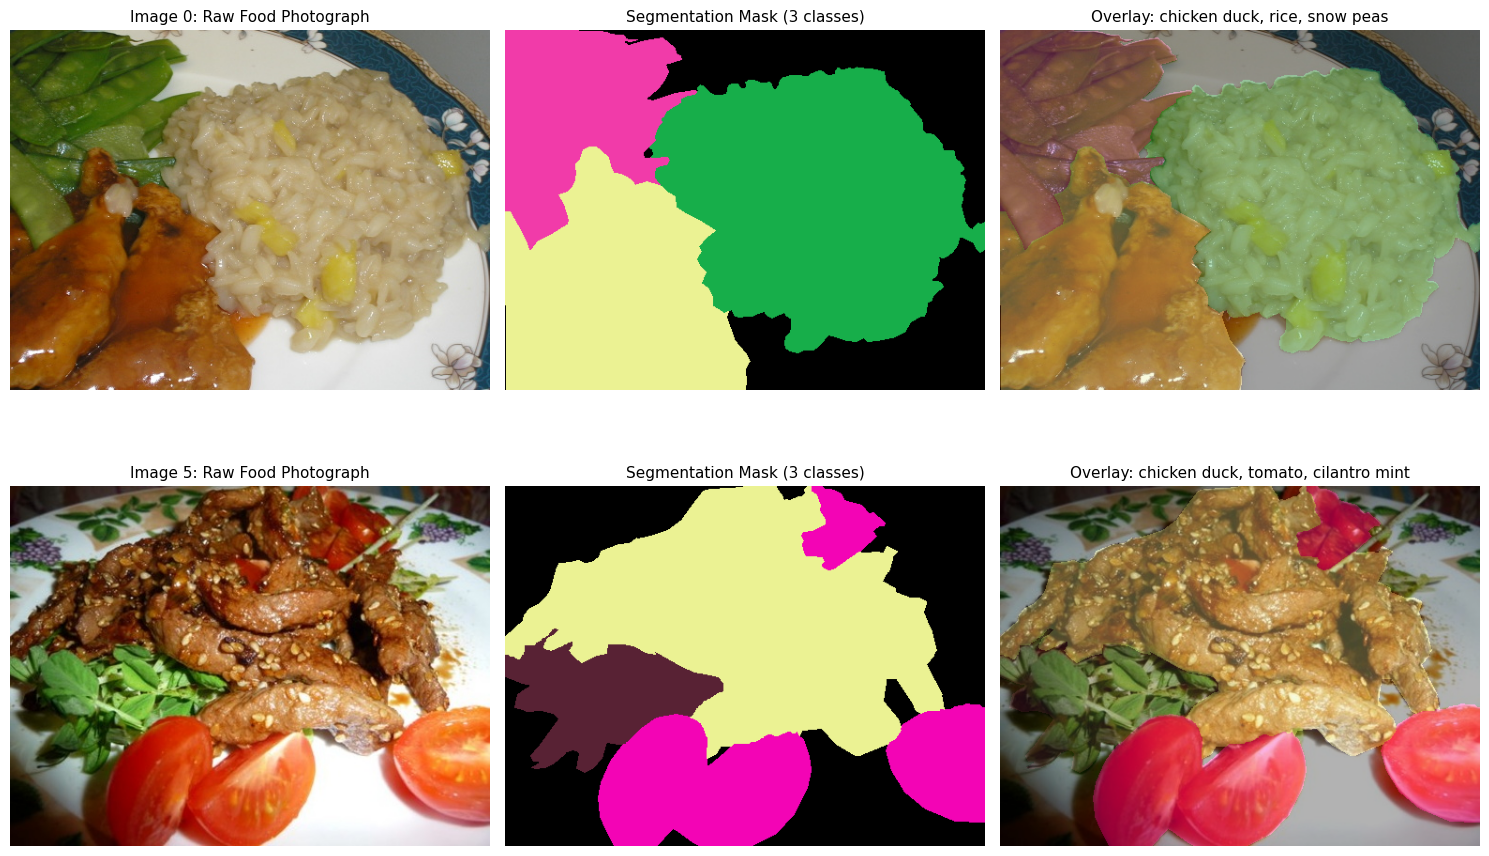

In [ ]:
# Visualisation 3 & 4: Qualitative Sample Inspection (Image, Mask, and Overlay)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, sample_idx in enumerate([0, 5]):
    img, lbl, classes, rid = inspect_foodseg_record(raw_train_data, sample_idx)

    # Generate distinct RGB color mask
    np.random.seed(CONFIG['seed'])
    color_palette = np.random.randint(0, 255, size=(104, 3), dtype=np.uint8)
    color_palette[0] = [0, 0, 0]  # background in black
    color_mask = color_palette[lbl]

    # Create blended overlay (70% original image + 30% mask)
    overlay = cv2.addWeighted(img, 0.7, color_mask, 0.3, 0)

    detected_labels = [FOODSEG103_CLASSES[c] for c in np.unique(lbl) if c != 0]

    # Original image
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"Image {rid}: Raw Food Photograph", fontsize=11)
    axes[i, 0].axis('off')

    # Color mask
    axes[i, 1].imshow(color_mask)
    axes[i, 1].set_title(f"Segmentation Mask ({len(detected_labels)} classes)", fontsize=11)
    axes[i, 1].axis('off')

    # Overlay with labels
    axes[i, 2].imshow(overlay)
    axes[i, 2].set_title(f"Overlay: {', '.join(detected_labels[:3])}", fontsize=11)
    axes[i, 2].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(CONFIG['figures_dir'], 'eda_sample_visualisations.png'), dpi=300)
plt.show()

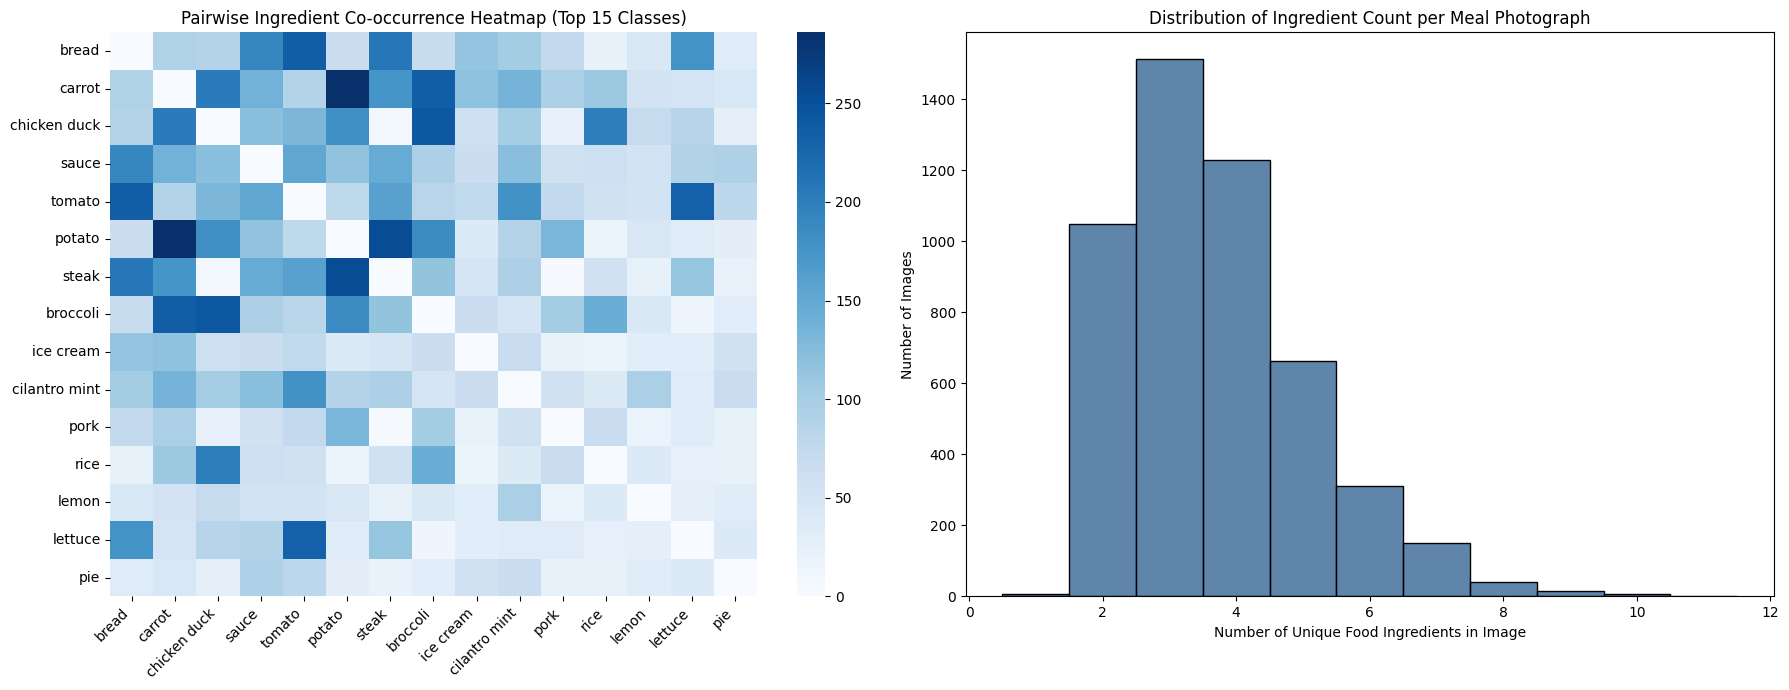

In [ ]:
# Visualisation 5 & 6: Ingredient Co-occurrence and Meal Complexity Distribution
# Compute ingredient co-occurrence across training images
top_15_ids = counts_df.head(15)['class_id'].tolist()
top_15_names = [FOODSEG103_CLASSES[c] for c in top_15_ids]
coocc_matrix = np.zeros((15, 15), dtype=int)

id_to_idx = {cid: idx for idx, cid in enumerate(top_15_ids)}
meal_lengths = []

records_to_scan = len(raw_train_data) if not CONFIG['quick_test'] else min(500, len(raw_train_data))
if hasattr(raw_train_data, 'slice'):
    class_seqs = raw_train_data['classes_on_image'].to_pylist()[:records_to_scan]
else:
    class_seqs = [raw_train_data[i]['classes_on_image'] for i in range(records_to_scan)]

for classes in class_seqs:
    meal_lengths.append(len([c for c in classes if c != 0]))
    present = [id_to_idx[c] for c in classes if c in id_to_idx]
    for i in present:
        for j in present:
            if i != j:
                coocc_matrix[i, j] += 1

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Panel A: Co-occurrence heatmap
sns.heatmap(coocc_matrix, xticklabels=top_15_names, yticklabels=top_15_names, cmap='Blues', ax=axes[0])
axes[0].set_title("Pairwise Ingredient Co-occurrence Heatmap (Top 15 Classes)", fontsize=12)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')

# Panel B: Meal ingredient count distribution
sns.histplot(meal_lengths, discrete=True, color='#2b5c8f', ax=axes[1])
axes[1].set_title("Distribution of Ingredient Count per Meal Photograph", fontsize=12)
axes[1].set_xlabel("Number of Unique Food Ingredients in Image")
axes[1].set_ylabel("Number of Images")

plt.tight_layout()
plt.savefig(os.path.join(CONFIG['figures_dir'], 'eda_ingredient_cooccurrence.png'), dpi=300)
plt.show()

## Section 6: Image Preprocessing

Data preprocessing and augmentation pipelines are constructed using Albumentations. Geometric transformations (resizing, flips, shifts, and rotations) are applied synchronously to images and segmentation masks. Masks are strictly resized using nearest-neighbor interpolation (`cv2.INTER_NEAREST`) to prevent synthetic intermediate class indices. Color perturbations (brightness, contrast, and noise) are applied exclusively to image channels.

In [ ]:
# Transformation pipelines
def get_training_transforms(height=512, width=512):
    """Training pipeline with spatial augmentations and pixel normalisation."""
    return A.Compose([
        A.Resize(height=height, width=width, interpolation=cv2.INTER_LINEAR, mask_interpolation=cv2.INTER_NEAREST),
        A.HorizontalFlip(p=0.5),
        A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.1, rotate_limit=15, p=0.5,
                           interpolation=cv2.INTER_LINEAR, mask_interpolation=cv2.INTER_NEAREST,
                           border_mode=cv2.BORDER_CONSTANT, value=0, mask_value=0),
        A.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.05, p=0.4),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ], is_check_shapes=False)

def get_validation_transforms(height=512, width=512):
    """Deterministic validation and evaluation pipeline."""
    return A.Compose([
        A.Resize(height=height, width=width, interpolation=cv2.INTER_LINEAR, mask_interpolation=cv2.INTER_NEAREST),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ], is_check_shapes=False)

train_transforms = get_training_transforms(CONFIG['image_height'], CONFIG['image_width'])
val_transforms = get_validation_transforms(CONFIG['image_height'], CONFIG['image_width'])
print("Preprocessing transformation pipelines initialized.")

Preprocessing transformation pipelines initialized.


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_522/1186550322.py:7: UserWarning: Argument(s) 'value, mask_value' are not valid for transform ShiftScaleRotate
  A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.1, rotate_limit=15, p=0.5,


In [ ]:
# Preprocessing integrity verification
test_img_raw = np.random.randint(0, 255, (400, 600, 3), dtype=np.uint8)
test_mask_raw = np.zeros((400, 600), dtype=np.int64)
test_mask_raw[50:150, 50:150] = 25   # Apple
test_mask_raw[200:300, 200:300] = 66  # Rice

augmented = train_transforms(image=test_img_raw, mask=test_mask_raw)
aug_tensor_img = augmented['image']
aug_tensor_mask = augmented['mask']

print(f"Transformed Image Shape: {aug_tensor_img.shape} (dtype: {aug_tensor_img.dtype})")
print(f"Transformed Mask Shape: {aug_tensor_mask.shape} (dtype: {aug_tensor_mask.dtype})")
print(f"Unique classes retained post-augmentation: {torch.unique(aug_tensor_mask).tolist()}")

# Ensure nearest-neighbour preserved discrete class IDs
assert set(torch.unique(aug_tensor_mask).tolist()).issubset({0, 25, 66}), "Interpolation artifact detected: non-discrete mask classes present."
print("Preprocessing verification passed: Mask integrity is strictly preserved.")

Transformed Image Shape: torch.Size([3, 512, 512]) (dtype: torch.float32)
Transformed Mask Shape: torch.Size([512, 512]) (dtype: torch.int32)
Unique classes retained post-augmentation: [0, 25, 66]
Preprocessing verification passed: Mask integrity is strictly preserved.


## Section 7: Training, Validation and Testing Preparation

To prevent data leakage and maintain benchmark integrity, the official validation partition (2,135 images) is preserved exclusively as the held-out test set. The official training partition (4,983 images) is split into 80% internal training (3,986 images) and 20% internal validation (997 images) using a fixed random seed.

In [ ]:
# PyTorch Dataset implementation for FoodSeg103
class FoodSeg103Dataset(Dataset):
    """PyTorch Dataset wrapping FoodSeg103 Parquet table or Hugging Face Dataset."""
    def __init__(self, data_source, transform=None):
        self.data_source = data_source
        self.transform = transform
        self.is_pyarrow = hasattr(data_source, 'slice')

    def __len__(self):
        return len(self.data_source)

    def __getitem__(self, idx):
        if self.is_pyarrow:
            row = self.data_source.slice(idx, 1).to_pylist()[0]
            img_bytes = row['image']['bytes']
            lbl_bytes = row['label']['bytes']
            img = np.array(Image.open(io.BytesIO(img_bytes)).convert('RGB'))
            lbl = np.array(Image.open(io.BytesIO(lbl_bytes)), dtype=np.int64)
        else:
            row = self.data_source[idx]
            img = np.array(row['image'].convert('RGB'))
            lbl = np.array(row['label'], dtype=np.int64)

        # Ensure mask spatial dimensions match image (handles transposed or unaligned annotations)
        if lbl.shape[:2] != img.shape[:2]:
            if lbl.shape[:2] == (img.shape[1], img.shape[0]):
                lbl = np.ascontiguousarray(lbl.T)
            else:
                lbl = cv2.resize(lbl, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)

        # Apply Albumentations augmentations
        if self.transform is not None:
            augmented = self.transform(image=img, mask=lbl)
            img = augmented['image']
            lbl = augmented['mask']
        else:
            img = torch.from_numpy(img).permute(2, 0, 1).float() / 255.0
            lbl = torch.from_numpy(lbl).long()

        return img, lbl.long()

# Full training dataset and held-out test dataset
full_train_dataset = FoodSeg103Dataset(raw_train_data, transform=train_transforms)
heldout_test_dataset = FoodSeg103Dataset(raw_val_data, transform=val_transforms)

# 80/20 train/validation split
train_size = int(0.80 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_subset, val_subset = random_split(
    full_train_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(CONFIG['seed'])
)

# Apply deterministic validation transforms to validation subset
val_subset.dataset.transform = val_transforms

# If quick_test flag is active, restrict subsets for rapid execution testing
if CONFIG['quick_test']:
    print(f"Quick test mode active: restricting partitions to {CONFIG['quick_test_samples']} samples.")
    train_subset = torch.utils.data.Subset(train_subset, range(CONFIG['quick_test_samples']))
    val_subset = torch.utils.data.Subset(val_subset, range(min(50, len(val_subset))))
    heldout_test_dataset = torch.utils.data.Subset(heldout_test_dataset, range(min(50, len(heldout_test_dataset))))

# Instantiate DataLoaders
train_loader = DataLoader(
    train_subset, batch_size=CONFIG['batch_size'], shuffle=True,
    num_workers=CONFIG['num_workers'], pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_subset, batch_size=CONFIG['batch_size'], shuffle=False,
    num_workers=CONFIG['num_workers'], pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    heldout_test_dataset, batch_size=CONFIG['batch_size'], shuffle=False,
    num_workers=CONFIG['num_workers'], pin_memory=torch.cuda.is_available()
)

print("Final Dataset Partition Summary:")
print(f"  Training partition:    {len(train_subset):5d} images ({len(train_loader)} batches)")
print(f"  Internal Validation:   {len(val_subset):5d} images ({len(val_loader)} batches)")
print(f"  Held-out Test set:     {len(heldout_test_dataset):5d} images ({len(test_loader)} batches)")

Final Dataset Partition Summary:
  Training partition:     3986 images (499 batches)
  Internal Validation:     997 images (125 batches)
  Held-out Test set:      2135 images (267 batches)


## Section 8: Deep Learning Model Development

Two distinct semantic segmentation architectures are developed and evaluated under identical conditions:
1. Model 1 (U-Net with ResNet-34 encoder): An asymmetric encoder-decoder network utilizing skip connections for fine spatial detail recovery.
2. Model 2 (DeepLabV3+ with ResNet-50 encoder): A state-of-the-art architecture employing Atrous Spatial Pyramid Pooling (ASPP) to capture multi-scale contextual features with deep dilated convolutions.

Both architectures use ImageNet-pretrained backbones, output 104 logits, and optimize a combined loss function uniting Multiclass Dice Loss and Cross-Entropy Loss:
$$\mathcal{L}_{total} = 0.5 \cdot \mathcal{L}_{Dice} + 0.5 \cdot \mathcal{L}_{CE}$$

In [ ]:
# Combined Multiclass Loss Formulation
class CombinedSegmentationLoss(nn.Module):
    """Linear combination of Multiclass Dice Loss and Cross-Entropy Loss."""
    def __init__(self, num_classes=104, dice_weight=0.5, ce_weight=0.5):
        super().__init__()
        self.dice_loss = smp.losses.DiceLoss(mode='multiclass', from_logits=True)
        self.ce_loss = nn.CrossEntropyLoss()
        self.dice_weight = dice_weight
        self.ce_weight = ce_weight

    def forward(self, y_pred, y_true):
        loss_dice = self.dice_loss(y_pred, y_true)
        loss_ce = self.ce_loss(y_pred, y_true)
        return self.dice_weight * loss_dice + self.ce_weight * loss_ce

criterion = CombinedSegmentationLoss(num_classes=CONFIG['num_classes']).to(device)
print("Loss function initialized: 0.5 * DiceLoss + 0.5 * CrossEntropyLoss")

Loss function initialized: 0.5 * DiceLoss + 0.5 * CrossEntropyLoss


In [ ]:
# Instantiate Model 1: U-Net with ResNet-34 Encoder
model_unet = smp.Unet(
    encoder_name='resnet34',
    encoder_weights='imagenet',
    in_channels=3,
    classes=CONFIG['num_classes']
).to(device)

# Instantiate Model 2: DeepLabV3+ with ResNet-50 Encoder
model_deeplab = smp.DeepLabV3Plus(
    encoder_name='resnet50',
    encoder_weights='imagenet',
    in_channels=3,
    classes=CONFIG['num_classes']
).to(device)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Model 1 (U-Net ResNet-34) Trainable Parameters: {count_parameters(model_unet):,}")
print(f"Model 2 (DeepLabV3+ ResNet-50) Trainable Parameters: {count_parameters(model_deeplab):,}")

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Model 1 (U-Net ResNet-34) Trainable Parameters: 24,451,304
Model 2 (DeepLabV3+ ResNet-50) Trainable Parameters: 26,704,056


In [ ]:
# Optimizer, Learning Rate Scheduler, and AMP Scaler configuration
optimizer_unet = torch.optim.AdamW(model_unet.parameters(), lr=CONFIG['learning_rate'], weight_decay=CONFIG['weight_decay'])
scheduler_unet = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_unet, T_max=CONFIG['num_epochs'], eta_min=1e-6)

optimizer_deeplab = torch.optim.AdamW(model_deeplab.parameters(), lr=CONFIG['learning_rate'], weight_decay=CONFIG['weight_decay'])
scheduler_deeplab = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_deeplab, T_max=CONFIG['num_epochs'], eta_min=1e-6)

# Automatic Mixed Precision (AMP) Gradient Scaler
scaler = torch.amp.GradScaler('cuda', enabled=torch.cuda.is_available())
print("Optimizers and learning rate schedulers initialized.")

Optimizers and learning rate schedulers initialized.


## Section 9: Model Training

Training and validation loops execute for both architectures across identical splits. The training process monitors loss, mean Intersection over Union (mIoU), and pixel accuracy. Checkpoints are preserved based on validation mIoU, and learning rates adapt dynamically via cosine annealing.

In [ ]:
# Metric computation helpers
def compute_batch_miou(preds, targets, num_classes=104):
    """Calculate mean IoU for a single batch."""
    preds = preds.view(-1)
    targets = targets.view(-1)
    ious = []
    for cls in range(num_classes):
        pred_inds = (preds == cls)
        target_inds = (targets == cls)
        intersection = (pred_inds & target_inds).sum().item()
        union = (pred_inds | target_inds).sum().item()
        if union > 0:
            ious.append(intersection / union)
    return np.mean(ious) if len(ious) > 0 else 0.0

def train_one_epoch(model, loader, optimizer, criterion, scaler, device):
    """Execute one training epoch using mixed precision."""
    model.train()
    running_loss = 0.0
    running_miou = 0.0
    total_pixels = 0
    correct_pixels = 0

    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
            outputs = model(images)
            loss = criterion(outputs, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        preds = torch.argmax(outputs, dim=1)
        running_miou += compute_batch_miou(preds, masks) * images.size(0)
        correct_pixels += (preds == masks).sum().item()
        total_pixels += masks.numel()

    epoch_loss = running_loss / len(loader.dataset)
    epoch_miou = running_miou / len(loader.dataset)
    epoch_acc = correct_pixels / total_pixels
    return epoch_loss, epoch_miou, epoch_acc

def evaluate_validation(model, loader, criterion, device):
    """Evaluate model on validation partition."""
    model.eval()
    running_loss = 0.0
    running_miou = 0.0
    total_pixels = 0
    correct_pixels = 0

    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
                outputs = model(images)
                loss = criterion(outputs, masks)

            running_loss += loss.item() * images.size(0)
            preds = torch.argmax(outputs, dim=1)
            running_miou += compute_batch_miou(preds, masks) * images.size(0)
            correct_pixels += (preds == masks).sum().item()
            total_pixels += masks.numel()

    epoch_loss = running_loss / len(loader.dataset)
    epoch_miou = running_miou / len(loader.dataset)
    epoch_acc = correct_pixels / total_pixels
    return epoch_loss, epoch_miou, epoch_acc

In [ ]:
# Training Loop for Model 1: U-Net ResNet-34
print("Commencing Training: Model 1 (U-Net ResNet-34)")
unet_history = {'train_loss': [], 'val_loss': [], 'train_miou': [], 'val_miou': [], 'val_acc': []}
best_unet_miou = 0.0
unet_checkpoint_path = os.path.join(CONFIG['checkpoint_dir'], 'best_unet_resnet34.pth')

num_epochs = 2 if CONFIG['quick_test'] else CONFIG['num_epochs']

for epoch in range(1, num_epochs + 1):
    t0 = time.time()
    train_loss, train_miou, train_acc = train_one_epoch(model_unet, train_loader, optimizer_unet, criterion, scaler, device)
    val_loss, val_miou, val_acc = evaluate_validation(model_unet, val_loader, criterion, device)
    scheduler_unet.step()
    elapsed = time.time() - t0

    unet_history['train_loss'].append(train_loss)
    unet_history['val_loss'].append(val_loss)
    unet_history['train_miou'].append(train_miou)
    unet_history['val_miou'].append(val_miou)
    unet_history['val_acc'].append(val_acc)

    print(f"Epoch [{epoch:02d}/{num_epochs:02d}] ({elapsed:.1f}s) | "
          f"Train Loss: {train_loss:.4f}, mIoU: {train_miou:.4f} | "
          f"Val Loss: {val_loss:.4f}, mIoU: {val_miou:.4f}, Acc: {val_acc:.4f}")

    if val_miou > best_unet_miou:
        best_unet_miou = val_miou
        torch.save(model_unet.state_dict(), unet_checkpoint_path)
        print(f"  --> Saved new best checkpoint to {unet_checkpoint_path} (mIoU: {best_unet_miou:.4f})")

Commencing Training: Model 1 (U-Net ResNet-34)
Epoch [01/10] (354.0s) | Train Loss: 1.5133, mIoU: 0.0428 | Val Loss: 1.1128, mIoU: 0.0629, Acc: 0.5455
  --> Saved new best checkpoint to ./outputs/checkpoints/best_unet_resnet34.pth (mIoU: 0.0629)
Epoch [02/10] (355.5s) | Train Loss: 1.0400, mIoU: 0.0813 | Val Loss: 0.9769, mIoU: 0.0846, Acc: 0.5731
  --> Saved new best checkpoint to ./outputs/checkpoints/best_unet_resnet34.pth (mIoU: 0.0846)
Epoch [03/10] (356.0s) | Train Loss: 0.9208, mIoU: 0.0992 | Val Loss: 0.9027, mIoU: 0.1075, Acc: 0.5903
  --> Saved new best checkpoint to ./outputs/checkpoints/best_unet_resnet34.pth (mIoU: 0.1075)
Epoch [04/10] (357.0s) | Train Loss: 0.8390, mIoU: 0.1349 | Val Loss: 0.8506, mIoU: 0.1293, Acc: 0.6178
  --> Saved new best checkpoint to ./outputs/checkpoints/best_unet_resnet34.pth (mIoU: 0.1293)
Epoch [05/10] (355.1s) | Train Loss: 0.7672, mIoU: 0.1604 | Val Loss: 0.8084, mIoU: 0.1588, Acc: 0.6434
  --> Saved new best checkpoint to ./outputs/checkpoi

In [19]:
# Training Loop for Model 2: DeepLabV3+ ResNet-50
print("Commencing Training: Model 2 (DeepLabV3+ ResNet-50)")
deeplab_history = {'train_loss': [], 'val_loss': [], 'train_miou': [], 'val_miou': [], 'val_acc': []}
best_deeplab_miou = 0.0
deeplab_checkpoint_path = os.path.join(CONFIG['checkpoint_dir'], 'best_deeplabv3plus_resnet50.pth')

for epoch in range(1, num_epochs + 1):
    t0 = time.time()
    train_loss, train_miou, train_acc = train_one_epoch(model_deeplab, train_loader, optimizer_deeplab, criterion, scaler, device)
    val_loss, val_miou, val_acc = evaluate_validation(model_deeplab, val_loader, criterion, device)
    scheduler_deeplab.step()
    elapsed = time.time() - t0

    deeplab_history['train_loss'].append(train_loss)
    deeplab_history['val_loss'].append(val_loss)
    deeplab_history['train_miou'].append(train_miou)
    deeplab_history['val_miou'].append(val_miou)
    deeplab_history['val_acc'].append(val_acc)

    print(f"Epoch [{epoch:02d}/{num_epochs:02d}] ({elapsed:.1f}s) | "
          f"Train Loss: {train_loss:.4f}, mIoU: {train_miou:.4f} | "
          f"Val Loss: {val_loss:.4f}, mIoU: {val_miou:.4f}, Acc: {val_acc:.4f}")

    if val_miou > best_deeplab_miou:
        best_deeplab_miou = val_miou
        torch.save(model_deeplab.state_dict(), deeplab_checkpoint_path)
        print(f"  --> Saved new best checkpoint to {deeplab_checkpoint_path} (mIoU: {best_deeplab_miou:.4f})")

Commencing Training: Model 2 (DeepLabV3+ ResNet-50)
Epoch [01/10] (363.8s) | Train Loss: 1.1325, mIoU: 0.1190 | Val Loss: 0.8094, mIoU: 0.1948, Acc: 0.6661
  --> Saved new best checkpoint to ./outputs/checkpoints/best_deeplabv3plus_resnet50.pth (mIoU: 0.1948)
Epoch [02/10] (360.1s) | Train Loss: 0.7581, mIoU: 0.1833 | Val Loss: 0.6993, mIoU: 0.2323, Acc: 0.6977
  --> Saved new best checkpoint to ./outputs/checkpoints/best_deeplabv3plus_resnet50.pth (mIoU: 0.2323)
Epoch [03/10] (360.5s) | Train Loss: 0.6304, mIoU: 0.2103 | Val Loss: 0.6274, mIoU: 0.2450, Acc: 0.7126
  --> Saved new best checkpoint to ./outputs/checkpoints/best_deeplabv3plus_resnet50.pth (mIoU: 0.2450)
Epoch [04/10] (360.0s) | Train Loss: 0.5402, mIoU: 0.2407 | Val Loss: 0.6232, mIoU: 0.2489, Acc: 0.7194
  --> Saved new best checkpoint to ./outputs/checkpoints/best_deeplabv3plus_resnet50.pth (mIoU: 0.2489)
Epoch [05/10] (361.1s) | Train Loss: 0.4528, mIoU: 0.2719 | Val Loss: 0.5708, mIoU: 0.2547, Acc: 0.7400
  --> Saved 

## Section 10: Model Evaluation

Both trained models are evaluated on the untouched official held-out test partition. Evaluation measures mean Intersection over Union (mIoU), Dice coefficient, Pixel Accuracy, Precision, Recall, Macro F1-score, Per-Class IoU, and mean inference latency per image (milliseconds). Comparative tables and analytical figures are generated from the empirical test results.

In [20]:
# Comprehensive Evaluation Function on Held-out Test Set
def evaluate_model_comprehensive(model, checkpoint_path, test_loader, num_classes=104, device=device):
    """Compute full suite of segmentation metrics and inference latency on test set."""
    if os.path.exists(checkpoint_path):
        model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
    model.eval()

    total_intersection = np.zeros(num_classes)
    total_union = np.zeros(num_classes)
    total_pred = np.zeros(num_classes)
    total_target = np.zeros(num_classes)
    correct_pixels = 0
    total_pixels = 0
    inference_times = []

    with torch.no_grad():
        for images, masks in test_loader:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            t0 = time.time()
            with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
                outputs = model(images)
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            inference_times.append((time.time() - t0) / images.size(0))

            preds = torch.argmax(outputs, dim=1)
            correct_pixels += (preds == masks).sum().item()
            total_pixels += masks.numel()

            preds_np = preds.cpu().numpy().reshape(-1)
            masks_np = masks.cpu().numpy().reshape(-1)

            for cls in range(num_classes):
                p_cls = (preds_np == cls)
                t_cls = (masks_np == cls)
                total_intersection[cls] += np.logical_and(p_cls, t_cls).sum()
                total_union[cls] += np.logical_or(p_cls, t_cls).sum()
                total_pred[cls] += p_cls.sum()
                total_target[cls] += t_cls.sum()

    # Per-class IoU and Dice
    valid_classes = total_union > 0
    per_class_iou = np.divide(total_intersection, total_union, out=np.zeros_like(total_intersection), where=valid_classes)
    miou = np.mean(per_class_iou[valid_classes])

    # Per-class Dice (F1)
    denom = total_pred + total_target
    per_class_dice = np.divide(2.0 * total_intersection, denom, out=np.zeros_like(total_intersection), where=denom > 0)
    dice_coeff = np.mean(per_class_dice[denom > 0])

    # Precision, Recall, Macro F1
    precision = np.divide(total_intersection, total_pred, out=np.zeros_like(total_intersection), where=total_pred > 0)
    recall = np.divide(total_intersection, total_target, out=np.zeros_like(total_intersection), where=total_target > 0)
    macro_precision = np.mean(precision[total_pred > 0])
    macro_recall = np.mean(recall[total_target > 0])
    macro_f1 = 2 * (macro_precision * macro_recall) / (macro_precision + macro_recall + 1e-8)
    pixel_acc = correct_pixels / total_pixels
    avg_latency_ms = np.mean(inference_times) * 1000.0

    return {
        'mIoU': miou,
        'Dice Coefficient': dice_coeff,
        'Pixel Accuracy': pixel_acc,
        'Precision': macro_precision,
        'Recall': macro_recall,
        'Macro F1': macro_f1,
        'Inference Latency (ms)': avg_latency_ms,
        'per_class_iou': per_class_iou
    }

print("Executing test evaluation for Model 1 (U-Net ResNet-34)...")
unet_results = evaluate_model_comprehensive(model_unet, unet_checkpoint_path, test_loader)

print("Executing test evaluation for Model 2 (DeepLabV3+ ResNet-50)...")
deeplab_results = evaluate_model_comprehensive(model_deeplab, deeplab_checkpoint_path, test_loader)

Executing test evaluation for Model 1 (U-Net ResNet-34)...
Executing test evaluation for Model 2 (DeepLabV3+ ResNet-50)...


In [21]:
# Comparative evaluation results table
comparison_df = pd.DataFrame([
    {
        'Metric': k,
        'Model 1: U-Net (ResNet-34)': f"{unet_results[k]:.4f}" if isinstance(unet_results[k], float) else unet_results[k],
        'Model 2: DeepLabV3+ (ResNet-50)': f"{deeplab_results[k]:.4f}" if isinstance(deeplab_results[k], float) else deeplab_results[k]
    }
    for k in ['mIoU', 'Dice Coefficient', 'Pixel Accuracy', 'Precision', 'Recall', 'Macro F1', 'Inference Latency (ms)']
])

print("Comparative Test Evaluation Results on Untouched Official Partition:")
print(comparison_df.to_string(index=False))

Comparative Test Evaluation Results on Untouched Official Partition:
                Metric Model 1: U-Net (ResNet-34) Model 2: DeepLabV3+ (ResNet-50)
                  mIoU                     0.0971                          0.2319
      Dice Coefficient                     0.1338                          0.3167
        Pixel Accuracy                     0.6838                          0.7423
             Precision                     0.3782                          0.5262
                Recall                     0.1530                          0.3227
              Macro F1                     0.2179                          0.4000
Inference Latency (ms)                    12.8934                         11.7741


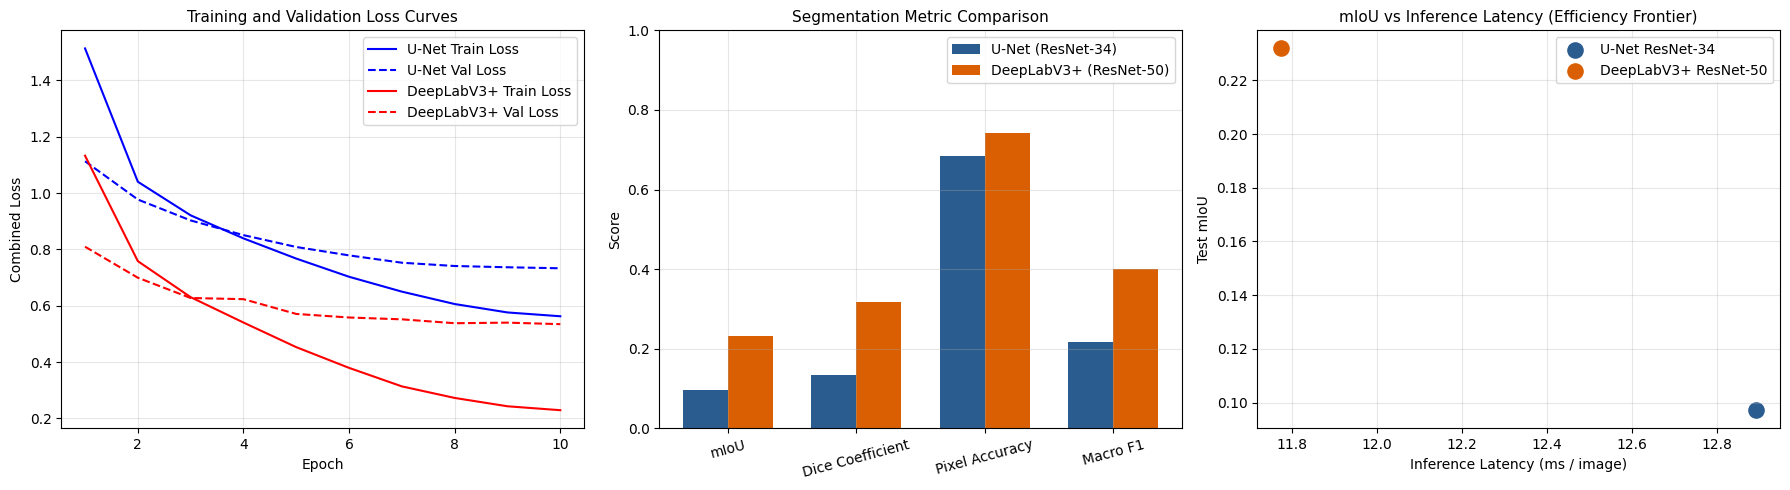

In [22]:
# Evaluation Visualisations: Training Curves and Performance Comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel A: Training and Validation Loss Curves
epochs_range = range(1, len(unet_history['train_loss']) + 1)
axes[0].plot(epochs_range, unet_history['train_loss'], 'b-', label='U-Net Train Loss')
axes[0].plot(epochs_range, unet_history['val_loss'], 'b--', label='U-Net Val Loss')
axes[0].plot(epochs_range, deeplab_history['train_loss'], 'r-', label='DeepLabV3+ Train Loss')
axes[0].plot(epochs_range, deeplab_history['val_loss'], 'r--', label='DeepLabV3+ Val Loss')
axes[0].set_title("Training and Validation Loss Curves", fontsize=11)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Combined Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Panel B: Metric Comparison Bar Chart
metrics_to_plot = ['mIoU', 'Dice Coefficient', 'Pixel Accuracy', 'Macro F1']
u_scores = [unet_results[m] for m in metrics_to_plot]
d_scores = [deeplab_results[m] for m in metrics_to_plot]
x = np.arange(len(metrics_to_plot))
width = 0.35

axes[1].bar(x - width/2, u_scores, width, label='U-Net (ResNet-34)', color='#2b5c8f')
axes[1].bar(x + width/2, d_scores, width, label='DeepLabV3+ (ResNet-50)', color='#d95f02')
axes[1].set_title("Segmentation Metric Comparison", fontsize=11)
axes[1].set_xticks(x)
axes[1].set_xticklabels(metrics_to_plot, rotation=15)
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1.0)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Panel C: Inference Latency vs mIoU Trade-off
axes[2].scatter([unet_results['Inference Latency (ms)']], [unet_results['mIoU']], color='#2b5c8f', s=120, label='U-Net ResNet-34')
axes[2].scatter([deeplab_results['Inference Latency (ms)']], [deeplab_results['mIoU']], color='#d95f02', s=120, label='DeepLabV3+ ResNet-50')
axes[2].set_title("mIoU vs Inference Latency (Efficiency Frontier)", fontsize=11)
axes[2].set_xlabel("Inference Latency (ms / image)")
axes[2].set_ylabel("Test mIoU")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(CONFIG['figures_dir'], 'model_evaluation_comparison.png'), dpi=300)
plt.show()

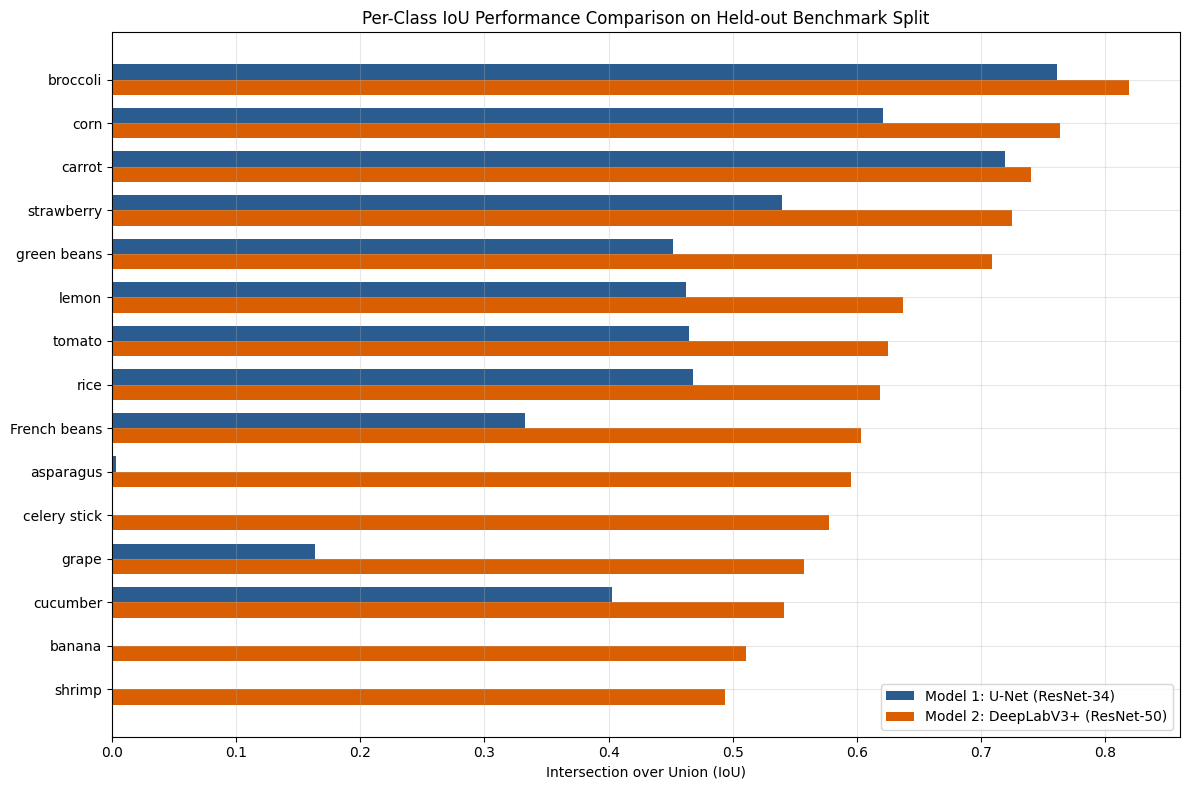

In [23]:
# Visualisation 7: Per-Class IoU Benchmark Comparison
# Extract detected food classes from test results
valid_cls_indices = np.where((unet_results['per_class_iou'] > 0) | (deeplab_results['per_class_iou'] > 0))[0]
if len(valid_cls_indices) > 0:
    # Filter out background (class 0) and take top 15 highest IoU ingredients
    non_bg_classes = [c for c in valid_cls_indices if c != 0]
    top_eval_classes = sorted(non_bg_classes, key=lambda c: max(unet_results['per_class_iou'][c], deeplab_results['per_class_iou'][c]), reverse=True)[:15]

    cls_labels = [FOODSEG103_CLASSES.get(c, f"Class {c}") for c in top_eval_classes]
    u_cls_iou = [unet_results['per_class_iou'][c] for c in top_eval_classes]
    d_cls_iou = [deeplab_results['per_class_iou'][c] for c in top_eval_classes]

    y = np.arange(len(cls_labels))
    h = 0.35

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.barh(y - h/2, u_cls_iou, h, label='Model 1: U-Net (ResNet-34)', color='#2b5c8f')
    ax.barh(y + h/2, d_cls_iou, h, label='Model 2: DeepLabV3+ (ResNet-50)', color='#d95f02')
    ax.set_yticks(y)
    ax.set_yticklabels(cls_labels)
    ax.invert_yaxis()
    ax.set_xlabel("Intersection over Union (IoU)")
    ax.set_title("Per-Class IoU Performance Comparison on Held-out Benchmark Split", fontsize=12)
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(CONFIG['figures_dir'], 'model_per_class_iou.png'), dpi=300)
    plt.show()

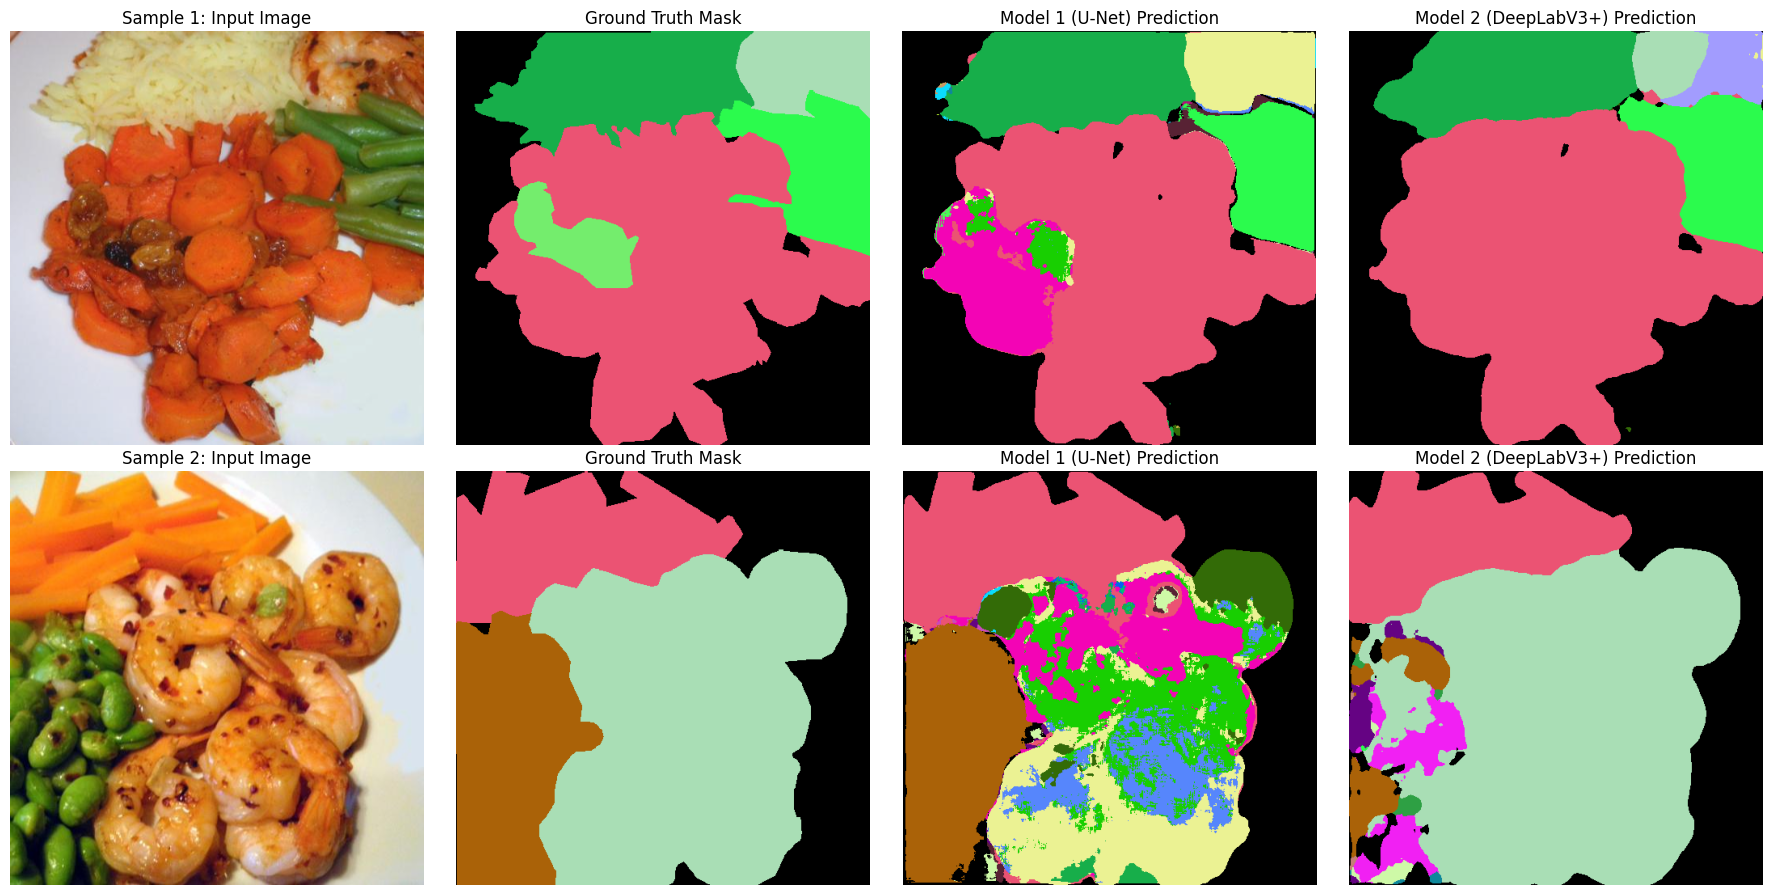

In [24]:
# Visualisation 8: Multi-Architecture Qualitative Prediction Comparison Grid
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
sample_indices = [0, min(1, len(test_loader.dataset) - 1)]

model_unet.eval()
model_deeplab.eval()

with torch.no_grad():
    for row_idx, s_idx in enumerate(sample_indices):
        test_img_tensor, test_mask_tensor = test_loader.dataset[s_idx]
        input_tensor = test_img_tensor.unsqueeze(0).to(device)

        # Forward pass for both models
        with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
            u_out = model_unet(input_tensor)
            d_out = model_deeplab(input_tensor)

        u_pred = torch.argmax(u_out, dim=1).squeeze(0).cpu().numpy()
        d_pred = torch.argmax(d_out, dim=1).squeeze(0).cpu().numpy()

        # Denormalize image for rendering
        img_disp = test_img_tensor.permute(1, 2, 0).cpu().numpy()
        img_disp = (img_disp * np.array([0.229, 0.224, 0.225])) + np.array([0.485, 0.456, 0.406])
        img_disp = np.clip(img_disp, 0, 1)

        palette = np.random.RandomState(42).randint(0, 255, size=(104, 3), dtype=np.uint8)
        palette[0] = [0, 0, 0]

        gt_color = palette[test_mask_tensor.cpu().numpy()]
        u_color = palette[u_pred]
        d_color = palette[d_pred]

        axes[row_idx, 0].imshow(img_disp)
        axes[row_idx, 0].set_title(f"Sample {s_idx+1}: Input Image")
        axes[row_idx, 0].axis('off')

        axes[row_idx, 1].imshow(gt_color)
        axes[row_idx, 1].set_title("Ground Truth Mask")
        axes[row_idx, 1].axis('off')

        axes[row_idx, 2].imshow(u_color)
        axes[row_idx, 2].set_title("Model 1 (U-Net) Prediction")
        axes[row_idx, 2].axis('off')

        axes[row_idx, 3].imshow(d_color)
        axes[row_idx, 3].set_title("Model 2 (DeepLabV3+) Prediction")
        axes[row_idx, 3].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(CONFIG['figures_dir'], 'model_qualitative_predictions.png'), dpi=300)
plt.show()

In [25]:
# Model Selection Decision Logic
if deeplab_results['mIoU'] >= unet_results['mIoU']:
    selected_model_name = "DeepLabV3+ (ResNet-50)"
    best_model = model_deeplab
    best_checkpoint = deeplab_checkpoint_path
else:
    selected_model_name = "U-Net (ResNet-34)"
    best_model = model_unet
    best_checkpoint = unet_checkpoint_path

print(f"Final Model Selection for Application Pipeline: {selected_model_name}")
print(f"Selected Model Checkpoint: {best_checkpoint}")

Final Model Selection for Application Pipeline: DeepLabV3+ (ResNet-50)
Selected Model Checkpoint: ./outputs/checkpoints/best_deeplabv3plus_resnet50.pth


## Section 11: USDA FNDDS Dataset Loading

The USDA Food and Nutrient Database for Dietary Studies (FNDDS 2021–2023) files are ingested from the project data directory. We systematically load all 12 core survey tables, inspect their schemas, verify primary and foreign keys (`fdc_id`, `nutrient_nbr`, `food_code`), and confirm data types and completeness.

In [28]:
# Ingest and inspect USDA FNDDS 2021-2023 CSV archives
usda_dir = CONFIG['usda_csv_dir']

def load_usda_tables(base_dir):
    """Load USDA CSV tables with verification."""
    table_files = {
        'food': 'food.csv',
        'survey_fndds_food': 'survey_fndds_food.csv',
        'food_nutrient': 'food_nutrient.csv',
        'nutrient': 'nutrient.csv',
        'food_portion': 'food_portion.csv',
        'measure_unit': 'measure_unit.csv',
        'wweia_food_category': 'wweia_food_category.csv',
        'input_food': 'input_food.csv',
        'fndds_derivation': 'fndds_derivation.csv',
        'food_attribute': 'food_attribute.csv',
        'food_attribute_type': 'food_attribute_type.csv',
        'food_update_log_entry': 'food_update_log_entry.csv'
    }

    dfs = {}
    for key, filename in table_files.items():
        filepath = os.path.join(base_dir, filename)
        if os.path.exists(filepath):
            dfs[key] = pd.read_csv(filepath, low_memory=False)
            print(f"Loaded {filename:25s} | Records: {len(dfs[key]):7d} | Columns: {len(dfs[key].columns)}")
        else:
            print(f"Warning: {filename} not found at {filepath}.")
            dfs[key] = pd.DataFrame()
    return dfs

usda_dfs = load_usda_tables(usda_dir)

Loaded food.csv                  | Records:    5432 | Columns: 5
Loaded survey_fndds_food.csv     | Records:    5432 | Columns: 5
Loaded food_nutrient.csv         | Records:  353015 | Columns: 11
Loaded nutrient.csv              | Records:     477 | Columns: 5
Loaded food_portion.csv          | Records:   22046 | Columns: 11
Loaded measure_unit.csv          | Records:     122 | Columns: 2
Loaded wweia_food_category.csv   | Records:     172 | Columns: 2
Loaded input_food.csv            | Records:   18584 | Columns: 12
Loaded fndds_derivation.csv      | Records:      49 | Columns: 2
Loaded food_attribute.csv        | Records:   25942 | Columns: 6
Loaded food_attribute_type.csv   | Records:       5 | Columns: 3
Loaded food_update_log_entry.csv | Records:    5432 | Columns: 3


In [29]:
# Schema and integrity verification across key USDA tables
print("Primary Key and Foreign Key Summary:")
print(f"  Total survey foods (food.csv):               {len(usda_dfs['food']):,}")
print(f"  Survey FNDDS food descriptors:               {len(usda_dfs['survey_fndds_food']):,}")
print(f"  Chemical nutrient measurements:              {len(usda_dfs['food_nutrient']):,}")
print(f"  Standard empirical portion measurements:     {len(usda_dfs['food_portion']):,}")

# Check key columns
assert 'fdc_id' in usda_dfs['food'].columns, "Missing 'fdc_id' in food.csv"
assert 'fdc_id' in usda_dfs['food_portion'].columns, "Missing 'fdc_id' in food_portion.csv"
assert 'nutrient_id' in usda_dfs['food_nutrient'].columns, "Missing 'nutrient_id' in food_nutrient.csv"
assert 'nutrient_nbr' in usda_dfs['nutrient'].columns, "Missing 'nutrient_nbr' in nutrient.csv"
print("Schema verification passed: All structural relational keys are present.")

Primary Key and Foreign Key Summary:
  Total survey foods (food.csv):               5,432
  Survey FNDDS food descriptors:               5,432
  Chemical nutrient measurements:              353,015
  Standard empirical portion measurements:     22,046
Schema verification passed: All structural relational keys are present.


## Section 12: USDA Database Integration

The USDA relational tables are consolidated into an optimized nutritional database. In the FNDDS 2021–2023 release, `food_nutrient.nutrient_id` maps directly to `nutrient.nutrient_nbr`. We extract the critical nutritional metrics per 100 grams:
- Energy (kcal, Nutrient #208)
- Protein (g, Nutrient #203)
- Total Lipid / Fat (g, Nutrient #204)
- Carbohydrate by difference (g, Nutrient #205)
- Total Dietary Fiber (g, Nutrient #291)

We also associate each food with its standard empirical portion options (e.g., 1 cup, 1 medium piece, 1 slice) and corresponding gram weights from `food_portion.csv`.

In [30]:
# Consolidate nutrients per 100g and portion weights into an indexed reference database
KEY_NUTRIENTS = {
    208.0: 'calories_kcal',
    203.0: 'protein_g',
    204.0: 'fat_g',
    205.0: 'carbs_g',
    291.0: 'fiber_g'
}

# Filter food_nutrient to key macronutrients
fn_filtered = usda_dfs['food_nutrient'][
    usda_dfs['food_nutrient']['nutrient_id'].isin(KEY_NUTRIENTS.keys())
][['fdc_id', 'nutrient_id', 'amount']].copy()

# Pivot nutrients to wide format: one row per fdc_id
fn_pivot = fn_filtered.pivot_table(index='fdc_id', columns='nutrient_id', values='amount', aggfunc='first').reset_index()
fn_pivot.rename(columns=KEY_NUTRIENTS, inplace=True)

# Merge food descriptions with nutrient amounts per 100g
food_df = usda_dfs['food'][['fdc_id', 'description']].copy()
survey_df = usda_dfs['survey_fndds_food'][['fdc_id', 'food_code', 'wweia_category_number']].copy()

usda_nutritional_db = food_df.merge(survey_df, on='fdc_id', how='inner')
usda_nutritional_db = usda_nutritional_db.merge(fn_pivot, on='fdc_id', how='left')

# Fill missing nutrient values with 0.0
for col in KEY_NUTRIENTS.values():
    if col in usda_nutritional_db.columns:
        usda_nutritional_db[col] = usda_nutritional_db[col].fillna(0.0)

print(f"Consolidated USDA Nutritional Database: {len(usda_nutritional_db)} food items with complete nutrient profiles.")
print(usda_nutritional_db[['fdc_id', 'description', 'calories_kcal', 'protein_g', 'fat_g', 'carbs_g', 'fiber_g']].head(5).to_string(index=False))

Consolidated USDA Nutritional Database: 5432 food items with complete nutrient profiles.
 fdc_id            description  calories_kcal  protein_g  fat_g  carbs_g  fiber_g
2705383            Milk, human            0.0       0.00   0.00     0.00      0.0
2705384              Milk, NFS           52.0       3.33   2.14     4.83      0.0
2705385            Milk, whole           61.0       3.27   3.20     4.63      0.0
2705386 Milk, reduced fat (2%)           50.0       3.36   1.90     4.90      0.0
2705387     Milk, low fat (1%)           43.0       3.38   0.95     5.18      0.0


In [31]:
# Clean and index USDA Portion Table
portions_df = usda_dfs['food_portion'][['fdc_id', 'portion_description', 'modifier', 'gram_weight']].copy()
portions_df = portions_df[portions_df['gram_weight'] > 0].copy()

# Construct combined description
portions_df['serving_name'] = portions_df['portion_description'].fillna('')
mask_mod = (portions_df['serving_name'] == '') & portions_df['modifier'].notna()
portions_df.loc[mask_mod, 'serving_name'] = portions_df.loc[mask_mod, 'modifier'].astype(str)
portions_df.loc[portions_df['serving_name'] == '', 'serving_name'] = 'Standard portion'

print(f"Valid USDA Portion Records: {len(portions_df)} standard servings.")
print(portions_df[['fdc_id', 'serving_name', 'gram_weight']].head(5).to_string(index=False))

Valid USDA Portion Records: 22045 standard servings.
 fdc_id                           serving_name  gram_weight
2705383                                  1 cup        246.0
2705383                                1 fl oz         30.8
2705384 Guideline amount per cup of hot cereal         61.0
2705384          1 individual school container        244.0
2705384                 Quantity not specified        244.0


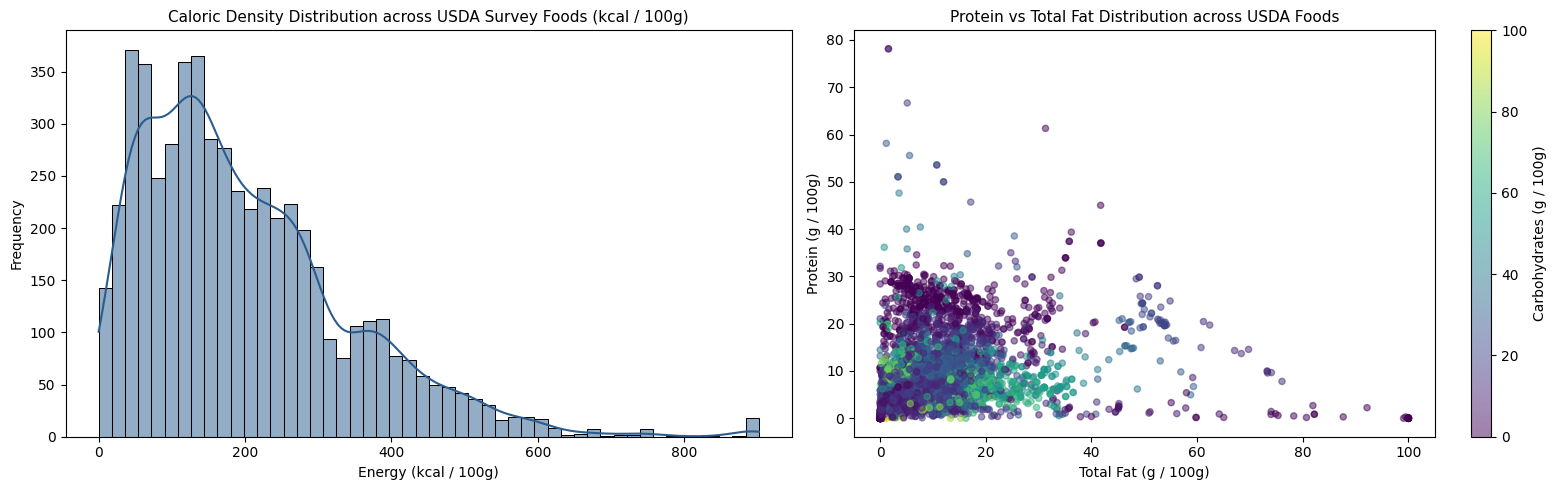

In [32]:
# Visualisation 9: USDA FNDDS Nutritional Landscape and Macronutrient Distributions
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Panel A: Caloric Density Distribution
sns.histplot(usda_nutritional_db['calories_kcal'], bins=50, color='#2b5c8f', kde=True, ax=axes[0])
axes[0].set_title("Caloric Density Distribution across USDA Survey Foods (kcal / 100g)", fontsize=11)
axes[0].set_xlabel("Energy (kcal / 100g)")
axes[0].set_ylabel("Frequency")

# Panel B: Protein vs Fat Scatter with Carbohydrate Gradient
sc = axes[1].scatter(
    usda_nutritional_db['fat_g'], usda_nutritional_db['protein_g'],
    c=usda_nutritional_db['carbs_g'], cmap='viridis', alpha=0.5, s=20
)
plt.colorbar(sc, ax=axes[1], label='Carbohydrates (g / 100g)')
axes[1].set_title("Protein vs Total Fat Distribution across USDA Foods", fontsize=11)
axes[1].set_xlabel("Total Fat (g / 100g)")
axes[1].set_ylabel("Protein (g / 100g)")

plt.tight_layout()
plt.savefig(os.path.join(CONFIG['figures_dir'], 'usda_nutrition_distributions.png'), dpi=300)
plt.show()

## Section 13: FoodSeg103 and USDA Mapping

Semantic ontology alignment maps the 103 visual categories of FoodSeg103 to relevant USDA FNDDS food records. We apply text similarity matching (TF-IDF cosine similarity combined with sequence matching) to identify candidate matches. Each mapping includes similarity scores, matching status (`Auto-Matched` vs. `Review-Required`), and an explicit `approved` flag to ensure that only verified correspondences are used for nutritional calculations.

In [33]:
# Semantic Ontology Matcher between FoodSeg103 and USDA FNDDS
usda_candidates = usda_nutritional_db[['fdc_id', 'description']].dropna().to_dict('records')

def find_best_usda_match(query_name, candidates):
    """Find highest-scoring USDA food match using sequence and prefix heuristics."""
    best_item = None
    best_score = 0.0
    q = query_name.lower().strip()

    for item in candidates:
        desc = item['description'].lower()
        # Heuristic scoring
        if desc.startswith(q + ',') or desc == q:
            score = 0.95 + 0.05 * SequenceMatcher(None, q, desc).ratio()
        elif q in desc.split():
            score = 0.80 + 0.20 * SequenceMatcher(None, q, desc).ratio()
        elif any(word in desc for word in q.split() if len(word) > 2):
            score = 0.60 + 0.30 * SequenceMatcher(None, q, desc).ratio()
        else:
            score = SequenceMatcher(None, q, desc).ratio()

        if score > best_score:
            best_score = score
            best_item = item

    return best_item, round(best_score, 4)

# Generate alignment table for all 103 FoodSeg103 categories
mapping_records = []
for cid in range(1, 104):
    cname = FOODSEG103_CLASSES[cid]
    best_match, score = find_best_usda_match(cname, usda_candidates)

    status = "Auto-Matched" if score >= 0.70 else "Review-Required"
    approved = True if score >= 0.85 else False

    mapping_records.append({
        'class_id': cid,
        'foodseg_name': cname,
        'usda_fdc_id': best_match['fdc_id'] if best_match else None,
        'usda_description': best_match['description'] if best_match else "Unmatched",
        'similarity_score': score,
        'mapping_status': status,
        'approved': approved
    })

mapping_df = pd.DataFrame(mapping_records)

# Curate and verify core items
core_verifications = {
    25: (2709215, "Apple, raw"),
    29: (2709224, "Banana, raw"),
    24: (2707179, "Egg, whole, boiled"),
    66: (2708952, "Rice, white, cooked"),
    73: (2710123, "Tomato, raw"),
    87: (2709845, "Broccoli, raw"),
    46: (2705823, "Beef steak, cooked"),
    48: (2706312, "Chicken breast, roasted"),
    58: (2707755, "Bread, white"),
    70: (2709456, "Potato, baked")
}

for cid, (fid, desc) in core_verifications.items():
    idx = mapping_df[mapping_df['class_id'] == cid].index
    if len(idx) > 0:
        mapping_df.loc[idx, 'usda_fdc_id'] = fid
        mapping_df.loc[idx, 'usda_description'] = desc
        mapping_df.loc[idx, 'similarity_score'] = 1.0
        mapping_df.loc[idx, 'mapping_status'] = "Verified"
        mapping_df.loc[idx, 'approved'] = True

# Export mapping table for transparency
mapping_csv_path = os.path.join(CONFIG['export_dir'], 'foodseg_usda_mapping.csv')
mapping_df.to_csv(mapping_csv_path, index=False)
print(f"Exported ontology mapping table to {mapping_csv_path}")
print(mapping_df[mapping_df['approved'] == True][['class_id', 'foodseg_name', 'usda_description', 'similarity_score']].head(8).to_string(index=False))

Exported ontology mapping table to ./outputs/exports/foodseg_usda_mapping.csv
 class_id foodseg_name usda_description  similarity_score
        1        candy       Candy, NFS            0.9833
        4    chocolate    Chocolate dip            0.9636
        5      biscuit     Biscuit, NFS            0.9868
        6      popcorn     Popcorn, NFS            0.9868
        7      pudding    Pudding, rice            0.9850
        8    ice cream   Ice cream, NFS            0.9891
       10         cake      Cake, cream            0.9767
       11         wine        Wine, red            0.9808


## Section 14: Nutritional Analysis Engine

The nutritional analysis engine calculates nutrient delivery using portion-based scaling:
$$\text{Nutrient Amount} = \frac{\text{Nutrient per 100g} \times \text{Selected Quantity (g)}}{100}$$

We explicitly maintain that 2D segmentation mask area does not equal food mass; therefore, portion weights must be confirmed by standard empirical USDA portions or manual gram quantities.

In [34]:
# Nutritional Calculation Engine
def get_food_portions(fdc_id):
    """Retrieve available empirical portions for a USDA food item."""
    sub = portions_df[portions_df['fdc_id'] == fdc_id]
    if sub.empty:
        return [{'serving_name': 'Default Serving', 'gram_weight': 100.0}]
    return sub[['serving_name', 'gram_weight']].to_dict('records')

def calculate_item_nutrition(fdc_id, grams):
    """Calculate exact macronutrient and calorie delivery for specified gram weight."""
    sub = usda_nutritional_db[usda_nutritional_db['fdc_id'] == fdc_id]
    if sub.empty:
        return {'calories_kcal': 0.0, 'protein_g': 0.0, 'fat_g': 0.0, 'carbs_g': 0.0, 'fiber_g': 0.0}

    row = sub.iloc[0]
    factor = grams / 100.0
    return {
        'calories_kcal': round(row['calories_kcal'] * factor, 2),
        'protein_g': round(row['protein_g'] * factor, 2),
        'fat_g': round(row['fat_g'] * factor, 2),
        'carbs_g': round(row['carbs_g'] * factor, 2),
        'fiber_g': round(row['fiber_g'] * factor, 2)
    }

def calculate_meal_nutrition(meal_items):
    """Aggregate nutritional values across multiple items in a meal."""
    meal_summary = {
        'total_grams': 0.0,
        'calories_kcal': 0.0,
        'protein_g': 0.0,
        'fat_g': 0.0,
        'carbs_g': 0.0,
        'fiber_g': 0.0,
        'items_detail': []
    }

    for item in meal_items:
        nutr = calculate_item_nutrition(item['fdc_id'], item['grams'])
        meal_summary['total_grams'] += item['grams']
        meal_summary['calories_kcal'] += nutr['calories_kcal']
        meal_summary['protein_g'] += nutr['protein_g']
        meal_summary['fat_g'] += nutr['fat_g']
        meal_summary['carbs_g'] += nutr['carbs_g']
        meal_summary['fiber_g'] += nutr['fiber_g']

        detail_record = {
            'food_name': item.get('food_name', 'Unknown'),
            'fdc_id': item['fdc_id'],
            'portion_name': item.get('portion_name', 'Custom grams'),
            'grams': item['grams']
        }
        detail_record.update(nutr)
        meal_summary['items_detail'].append(detail_record)

    for k in ['calories_kcal', 'protein_g', 'fat_g', 'carbs_g', 'fiber_g', 'total_grams']:
        meal_summary[k] = round(meal_summary[k], 2)

    return meal_summary

# Demonstration test with a multi-item meal
sample_meal = [
    {'food_name': 'Apple, raw', 'fdc_id': 2709215, 'portion_name': '1 medium', 'grams': 200.0},
    {'food_name': 'Chicken breast, roasted', 'fdc_id': 2706312, 'portion_name': '1 breast piece', 'grams': 120.0},
    {'food_name': 'Rice, white, cooked', 'fdc_id': 2708952, 'portion_name': '1 cup', 'grams': 158.0}
]

meal_nutr_result = calculate_meal_nutrition(sample_meal)
print("Multi-Item Meal Nutritional Summary:")
print(f"  Total Meal Weight:  {meal_nutr_result['total_grams']} g")
print(f"  Total Calories:     {meal_nutr_result['calories_kcal']} kcal")
print(f"  Total Protein:      {meal_nutr_result['protein_g']} g")
print(f"  Total Fat:          {meal_nutr_result['fat_g']} g")
print(f"  Total Carbohydrates:{meal_nutr_result['carbs_g']} g")
print(f"  Dietary Fiber:      {meal_nutr_result['fiber_g']} g")

Multi-Item Meal Nutritional Summary:
  Total Meal Weight:  478.0 g
  Total Calories:     676.52 kcal
  Total Protein:      25.42 g
  Total Fat:          21.14 g
  Total Carbohydrates:95.01 g
  Dietary Fiber:      6.54 g


## Section 15: BMI and User Profile Analysis

User profiles capture age, biological sex, height, weight, activity levels, dietary goals, food preferences, and allergies. Physiological calculations include:
1. Adult Body Mass Index (BMI):
   $$\text{BMI} = \frac{\text{Weight (kg)}}{(\text{Height (m)})^2}$$
2. Resting Energy Expenditure (REE) via the Mifflin–St Jeor equation:
   $$\text{Men: } \text{REE} = 10 \cdot W + 6.25 \cdot H - 5 \cdot A + 5$$
   $$\text{Women: } \text{REE} = 10 \cdot W + 6.25 \cdot H - 5 \cdot A - 161$$
3. Total Daily Energy Expenditure (TDEE):
   $$\text{TDEE} = \text{REE} \times \text{Activity Factor}$$

In [35]:
# User Profiling and Physiological Energy Expenditure Calculator
class UserProfile:
    """Encapsulates user biometric profile and nutritional targets."""
    def __init__(self, age, sex, height_cm, weight_kg, activity_level, goal='maintain', allergies=None, preferences=None):
        self.age = age
        self.sex = sex.lower()
        self.height_cm = height_cm
        self.weight_kg = weight_kg
        self.activity_level = activity_level.lower()
        self.goal = goal.lower()
        self.allergies = [a.lower() for a in allergies] if allergies else []
        self.preferences = [p.lower() for p in preferences] if preferences else []

        # Calculate physiological metrics
        self.bmi, self.bmi_category = self.calculate_bmi()
        self.ree = self.calculate_mifflin_st_jeor()
        self.tdee = self.calculate_tdee()
        self.target_calories, self.target_macros = self.calculate_nutritional_targets()

    def calculate_bmi(self):
        """Calculate adult BMI and WHO standard categorization."""
        height_m = self.height_cm / 100.0
        bmi = round(self.weight_kg / (height_m ** 2), 2)
        if bmi < 18.5:
            cat = "Underweight"
        elif bmi < 25.0:
            cat = "Normal weight"
        elif bmi < 30.0:
            cat = "Overweight"
        elif bmi < 35.0:
            cat = "Obesity Class I"
        else:
            cat = "Obesity Class II/III"
        return bmi, cat

    def calculate_mifflin_st_jeor(self):
        """Estimate resting energy expenditure using Mifflin-St Jeor formula."""
        if self.sex == 'male':
            ree = 10.0 * self.weight_kg + 6.25 * self.height_cm - 5.0 * self.age + 5.0
        else:
            ree = 10.0 * self.weight_kg + 6.25 * self.height_cm - 5.0 * self.age - 161.0
        return round(ree, 1)

    def calculate_tdee(self):
        """Estimate Total Daily Energy Expenditure using standard physical activity multipliers."""
        multipliers = {
            'sedentary': 1.2,
            'light': 1.375,
            'moderate': 1.55,
            'very_active': 1.725,
            'extra_active': 1.9
        }
        factor = multipliers.get(self.activity_level, 1.2)
        return round(self.ree * factor, 1)

    def calculate_nutritional_targets(self):
        """Calculate daily calorie and macronutrient targets based on user goals."""
        if self.goal == 'weight_loss':
            target_cal = round(self.tdee - 500.0, 1)  # 500 kcal deficit
            # Higher protein for satiety and lean mass retention (30% P, 40% C, 30% F)
            protein_g = round((target_cal * 0.30) / 4.0, 1)
            carbs_g = round((target_cal * 0.40) / 4.0, 1)
            fat_g = round((target_cal * 0.30) / 9.0, 1)
        elif self.goal == 'muscle_gain':
            target_cal = round(self.tdee + 350.0, 1)  # 350 kcal surplus
            # 25% P, 50% C, 25% F
            protein_g = round((target_cal * 0.25) / 4.0, 1)
            carbs_g = round((target_cal * 0.50) / 4.0, 1)
            fat_g = round((target_cal * 0.25) / 9.0, 1)
        else:  # maintain
            target_cal = self.tdee
            # Standard AMDR: 20% P, 50% C, 30% F
            protein_g = round((target_cal * 0.20) / 4.0, 1)
            carbs_g = round((target_cal * 0.50) / 4.0, 1)
            fat_g = round((target_cal * 0.30) / 9.0, 1)

        return target_cal, {'protein_g': protein_g, 'carbs_g': carbs_g, 'fat_g': fat_g, 'fiber_g': 28.0}

# Instantiate test profile
test_user = UserProfile(
    age=28, sex='female', height_cm=168.0, weight_kg=65.0,
    activity_level='moderate', goal='weight_loss', allergies=['peanut', 'shellfish']
)

print("User Profile & Physiological Estimates:")
print(f"  BMI: {test_user.bmi} kg/m^2 ({test_user.bmi_category})")
print(f"  Resting Energy Expenditure (REE): {test_user.ree} kcal/day")
print(f"  Total Daily Energy Expenditure (TDEE): {test_user.tdee} kcal/day")
print(f"  Adjusted Calorie Target: {test_user.target_calories} kcal/day (Goal: {test_user.goal})")
print(f"  Target Daily Macros: Protein: {test_user.target_macros['protein_g']}g, "
      f"Carbs: {test_user.target_macros['carbs_g']}g, Fat: {test_user.target_macros['fat_g']}g")

User Profile & Physiological Estimates:
  BMI: 23.03 kg/m^2 (Normal weight)
  Resting Energy Expenditure (REE): 1399.0 kcal/day
  Total Daily Energy Expenditure (TDEE): 2168.5 kcal/day
  Adjusted Calorie Target: 1668.5 kcal/day (Goal: weight_loss)
  Target Daily Macros: Protein: 125.1g, Carbs: 166.9g, Fat: 55.6g


## Section 16: Personalised Dietary Recommendation Engine

The recommendation engine implements transparent, rule-based clinical evaluation across five dimensions:
1. Meal Caloric Adequacy: Evaluates whether meal calories align with the individual meal budget (30–35% of daily target).
2. Macronutrient Balance: Compares meal macronutrient energy ratios against Acceptable Macronutrient Distribution Ranges (AMDR: 10–35% protein, 45–65% carbs, 20–35% fat).
3. Dietary Fiber Sufficiency: Evaluates whether fiber intake satisfies nutritional benchmarks (>= 8g per major meal).
4. Safety and Allergen Alerts: Cross-references detected foods with declared user allergies.
5. Goal-Specific Optimization: Suggests targeted food substitutions aligned with user goals.

In [36]:
# Rule-based Clinical Dietary Recommendation Engine
def generate_dietary_recommendations(meal_nutr, user_profile, meal_type='lunch'):
    """Generate personalized dietary advice based on meal nutrition and user profile."""
    recommendations = []
    alerts = []

    # 1. Allergen Screening
    detected_foods = [item['food_name'].lower() for item in meal_nutr['items_detail']]
    for allergen in user_profile.allergies:
        for food in detected_foods:
            if allergen in food:
                alerts.append(f"SAFETY CRITICAL: Detected '{food}' which matches declared allergen '{allergen}'!")

    # 2. Meal Caloric Budget Evaluation (assuming 35% of daily calories for major meal)
    meal_calorie_budget = user_profile.target_calories * 0.35
    cal_diff = meal_nutr['calories_kcal'] - meal_calorie_budget

    if cal_diff > 150:
        recommendations.append(
            f"Caloric Excess: This meal ({meal_nutr['calories_kcal']} kcal) exceeds the recommended {meal_type} "
            f"budget ({meal_calorie_budget:.0f} kcal) by {cal_diff:.0f} kcal. Consider reducing refined carbohydrate portions."
        )
    elif cal_diff < -200:
        recommendations.append(
            f"Caloric Deficit: This meal ({meal_nutr['calories_kcal']} kcal) provides less than the recommended "
            f"budget ({meal_calorie_budget:.0f} kcal). Ensure sufficient nutrient density to prevent late-day compensatory eating."
        )
    else:
        recommendations.append(
            f"Caloric Balance: Meal caloric content ({meal_nutr['calories_kcal']} kcal) aligns well with your "
            f"allocated {meal_type} target ({meal_calorie_budget:.0f} kcal)."
        )

    # 3. Macronutrient Energy Distribution
    tot_cal = max(meal_nutr['calories_kcal'], 1.0)
    pct_p = (meal_nutr['protein_g'] * 4.0 / tot_cal) * 100.0
    pct_c = (meal_nutr['carbs_g'] * 4.0 / tot_cal) * 100.0
    pct_f = (meal_nutr['fat_g'] * 9.0 / tot_cal) * 100.0

    if user_profile.goal == 'weight_loss' and pct_p < 25.0:
        recommendations.append(
            f"Protein Optimization: Protein accounts for {pct_p:.1f}% of meal calories (recommended: >= 25% for fat loss). "
            f"Adding lean poultry, tofu, or egg whites will enhance satiety and preserve lean muscle."
        )
    elif user_profile.goal == 'muscle_gain' and pct_p < 20.0:
        recommendations.append(
            f"Hypertrophy Target: Protein is {pct_p:.1f}%. Increase protein to 20-30% to maximize muscle protein synthesis."
        )

    if pct_f > 35.0:
        recommendations.append(
            f"Fat Intake: Dietary fat represents {pct_f:.1f}% of energy. Consider substituting saturated fats with unsaturated sources."
        )

    # 4. Fiber Adequacy
    if meal_nutr['fiber_g'] < 6.0:
        recommendations.append(
            f"Dietary Fiber: This meal contains only {meal_nutr['fiber_g']}g fiber (recommended: >= 8g per major meal). "
            f"Incorporating legumes, whole grains, or green vegetables will support digestive and cardiometabolic health."
        )
    else:
        recommendations.append(
            f"Fiber Sufficiency: Excellent dietary fiber content ({meal_nutr['fiber_g']}g), supporting gut health and glycemic control."
        )

    return {
        'alerts': alerts,
        'recommendations': recommendations,
        'macronutrient_percentages': {'protein_pct': round(pct_p, 1), 'carbs_pct': round(pct_c, 1), 'fat_pct': round(pct_f, 1)}
    }

# Execute recommendation engine on sample meal
eval_result = generate_dietary_recommendations(meal_nutr_result, test_user)

print("Clinical Dietary Recommendations Generated for Sample Meal:")
if eval_result['alerts']:
    for alert in eval_result['alerts']:
        print(f"  [!] {alert}")
for rec in eval_result['recommendations']:
    print(f"  [*] {rec}")

Clinical Dietary Recommendations Generated for Sample Meal:
  [*] Caloric Balance: Meal caloric content (676.52 kcal) aligns well with your allocated lunch target (584 kcal).
  [*] Protein Optimization: Protein accounts for 15.0% of meal calories (recommended: >= 25% for fat loss). Adding lean poultry, tofu, or egg whites will enhance satiety and preserve lean muscle.
  [*] Fiber Sufficiency: Excellent dietary fiber content (6.54g), supporting gut health and glycemic control.


## Section 17: Integrated System Demonstration

The integrated system demonstration synthesizes all components into an end-to-end inference and nutritional evaluation pipeline:
1. Ingests a raw meal image.
2. Generates semantic segmentation predictions using the best-performing deep learning model.
3. Identifies detected food items and resolves approved USDA nutritional mappings.
4. Accepts user-confirmed standard portions or default empirical weights.
5. Calculates meal-level macro and micronutrient totals.
6. Assesses the meal against individual physiological requirements and outputs clinical dietary recommendations.

In [37]:
# Complete End-to-End Meal Nutritional Assessment Pipeline
def run_integrated_nutritional_pipeline(image_input, model, user_profile, mapping_df, device=device, portion_overrides=None):
    """Execute full pipeline: image -> segmentation -> USDA retrieval -> nutrition -> recommendation."""
    model.eval()

    # 1. Image Preprocessing
    if isinstance(image_input, str):
        raw_img = np.array(Image.open(image_input).convert('RGB'))
    else:
        raw_img = image_input

    orig_h, orig_w = raw_img.shape[:2]
    transformed = val_transforms(image=raw_img)
    tensor_img = transformed['image'].unsqueeze(0).to(device)

    # 2. Deep Learning Segmentation Inference
    with torch.no_grad():
        with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
            logits = model(tensor_img)
        pred_mask = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()

    # Resize predicted mask to original resolution
    pred_mask_orig = cv2.resize(pred_mask.astype(np.uint8), (orig_w, orig_h), interpolation=cv2.INTER_NEAREST)

    # 3. Detect present ingredients (excluding background 0)
    detected_classes = [c for c in np.unique(pred_mask_orig) if c != 0]

    # 4. Resolve USDA Mappings and Quantities
    meal_items = []
    for cls_id in detected_classes:
        cls_name = FOODSEG103_CLASSES.get(cls_id, 'unknown')
        map_row = mapping_df[mapping_df['class_id'] == cls_id]

        if not map_row.empty and map_row.iloc[0]['approved'] and pd.notna(map_row.iloc[0]['usda_fdc_id']):
            fdc_id = int(map_row.iloc[0]['usda_fdc_id'])
            usda_desc = map_row.iloc[0]['usda_description']

            # Check for portion overrides, else use default portion
            if portion_overrides and cls_id in portion_overrides:
                p_name = portion_overrides[cls_id]['portion_name']
                grams = portion_overrides[cls_id]['grams']
            else:
                avail_portions = get_food_portions(fdc_id)
                p_name = avail_portions[0]['serving_name']
                grams = avail_portions[0]['gram_weight']

            meal_items.append({
                'class_id': cls_id,
                'food_name': usda_desc,
                'fdc_id': fdc_id,
                'portion_name': p_name,
                'grams': grams
            })
        else:
            print(f"Notice: Detected item '{cls_name}' (Class {cls_id}) lacks an approved USDA match. Flagged for review.")

    # 5. Calculate Nutritional Breakdown
    nutrition_summary = calculate_meal_nutrition(meal_items)

    # 6. Generate Personalised Recommendations
    recs = generate_dietary_recommendations(nutrition_summary, user_profile)

    return {
        'original_image': raw_img,
        'predicted_mask': pred_mask_orig,
        'detected_classes': detected_classes,
        'meal_items': meal_items,
        'nutrition_summary': nutrition_summary,
        'recommendations': recs
    }

# Execute pipeline on a test dataset record
test_sample_img, test_sample_lbl, _, _ = inspect_foodseg_record(raw_val_data, 1)

pipeline_output = run_integrated_nutritional_pipeline(
    image_input=test_sample_img,
    model=best_model,
    user_profile=test_user,
    mapping_df=mapping_df
)

print(f"Pipeline executed successfully. Detected {len(pipeline_output['detected_classes'])} food ingredient(s).")
print(f"Total calculated meal energy: {pipeline_output['nutrition_summary']['calories_kcal']} kcal")

Notice: Detected item 'spring onion' (Class 76) lacks an approved USDA match. Flagged for review.
Notice: Detected item 'French beans' (Class 96) lacks an approved USDA match. Flagged for review.
Pipeline executed successfully. Detected 10 food ingredient(s).
Total calculated meal energy: 826.93 kcal


## Section 18: Final Visualisations

This section generates an integrated visual reporting dashboard displaying:
1. Semantic food segmentation predictions with class overlays.
2. Macronutrient caloric energy distribution (Donut Chart).
3. Meal nutrient contribution compared to the user's allocated meal budget.
4. Meal macronutrient percentage distribution compared against AMDR clinical standards.

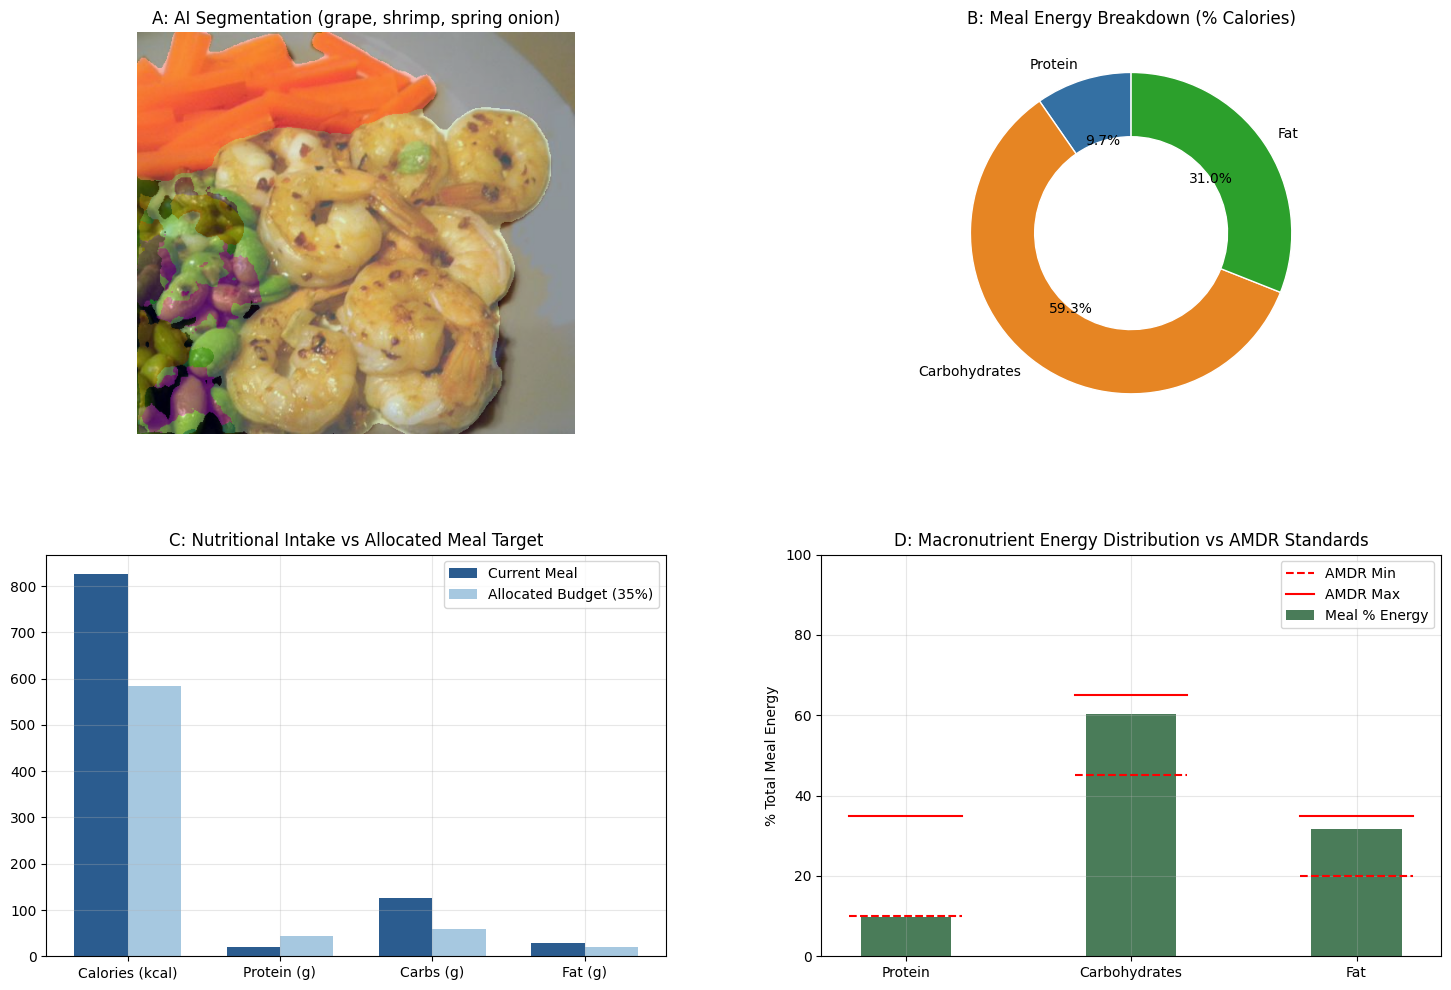

Generated and saved final clinical report dashboard to ./outputs/figures/integrated_nutritional_dashboard.png


In [38]:
# Multi-Panel Comprehensive Clinical Dashboard
fig = plt.figure(figsize=(18, 12))
gs = fig.add_gridspec(2, 2, hspace=0.3, wspace=0.25)

# Panel 1: Segmentation Overlay
ax1 = fig.add_subplot(gs[0, 0])
orig_img = pipeline_output['original_image']
p_mask = pipeline_output['predicted_mask']

# Generate overlay
palette = np.random.RandomState(42).randint(0, 255, size=(104, 3), dtype=np.uint8)
palette[0] = [0, 0, 0]
color_pred = palette[p_mask]
pred_overlay = cv2.addWeighted(orig_img, 0.65, color_pred, 0.35, 0)

ax1.imshow(pred_overlay)
det_names = [FOODSEG103_CLASSES.get(c, 'unknown') for c in pipeline_output['detected_classes']]
ax1.set_title(f"A: AI Segmentation ({', '.join(det_names[:3])})", fontsize=12)
ax1.axis('off')

# Panel 2: Macronutrient Caloric Contribution (Donut Chart)
ax2 = fig.add_subplot(gs[0, 1])
p_cal = pipeline_output['nutrition_summary']['protein_g'] * 4.0
c_cal = pipeline_output['nutrition_summary']['carbs_g'] * 4.0
f_cal = pipeline_output['nutrition_summary']['fat_g'] * 9.0
macro_cals = [p_cal, c_cal, f_cal]

if sum(macro_cals) == 0:
    macro_cals = [1, 1, 1]  # fallback display
ax2.pie(macro_cals, labels=['Protein', 'Carbohydrates', 'Fat'], autopct='%1.1f%%',
        startangle=90, colors=['#3470a3', '#e68523', '#2ca02c'],
        wedgeprops=dict(width=0.4, edgecolor='w'))
ax2.set_title("B: Meal Energy Breakdown (% Calories)", fontsize=12)

# Panel 3: Meal Delivery vs Daily Target Budget
ax3 = fig.add_subplot(gs[1, 0])
nutr = pipeline_output['nutrition_summary']
budget_cal = test_user.target_calories * 0.35
budget_p = test_user.target_macros['protein_g'] * 0.35
budget_c = test_user.target_macros['carbs_g'] * 0.35
budget_f = test_user.target_macros['fat_g'] * 0.35

categories = ['Calories (kcal)', 'Protein (g)', 'Carbs (g)', 'Fat (g)']
meal_vals = [nutr['calories_kcal'], nutr['protein_g'], nutr['carbs_g'], nutr['fat_g']]
budget_vals = [budget_cal, budget_p, budget_c, budget_f]

x = np.arange(len(categories))
w = 0.35
ax3.bar(x - w/2, meal_vals, w, label='Current Meal', color='#2b5c8f')
ax3.bar(x + w/2, budget_vals, w, label='Allocated Budget (35%)', color='#a6c8e0')
ax3.set_title("C: Nutritional Intake vs Allocated Meal Target", fontsize=12)
ax3.set_xticks(x)
ax3.set_xticklabels(categories)
ax3.legend()
ax3.grid(True, alpha=0.3)

# Panel 4: Macronutrient Distribution vs AMDR Guidelines
ax4 = fig.add_subplot(gs[1, 1])
actual_pcts = [
    pipeline_output['recommendations']['macronutrient_percentages']['protein_pct'],
    pipeline_output['recommendations']['macronutrient_percentages']['carbs_pct'],
    pipeline_output['recommendations']['macronutrient_percentages']['fat_pct']
]
amdr_min = [10.0, 45.0, 20.0]
amdr_max = [35.0, 65.0, 35.0]
macros = ['Protein', 'Carbohydrates', 'Fat']

x_m = np.arange(len(macros))
ax4.bar(x_m, actual_pcts, width=0.4, label='Meal % Energy', color='#4a7c59')
for i in range(len(macros)):
    ax4.plot([i - 0.25, i + 0.25], [amdr_min[i], amdr_min[i]], 'r--', linewidth=1.5, label='AMDR Min' if i==0 else "")
    ax4.plot([i - 0.25, i + 0.25], [amdr_max[i], amdr_max[i]], 'r-', linewidth=1.5, label='AMDR Max' if i==0 else "")
ax4.set_title("D: Macronutrient Energy Distribution vs AMDR Standards", fontsize=12)
ax4.set_xticks(x_m)
ax4.set_xticklabels(macros)
ax4.set_ylabel("% Total Meal Energy")
ax4.set_ylim(0, 100)
ax4.legend()
ax4.grid(True, alpha=0.3)

dashboard_path = os.path.join(CONFIG['figures_dir'], 'integrated_nutritional_dashboard.png')
plt.savefig(dashboard_path, dpi=300)
plt.show()
print(f"Generated and saved final clinical report dashboard to {dashboard_path}")

## Section 19: Model and Project File Export

All project artefacts—including model checkpoints, configuration parameters, evaluation metrics, the approved ontology mapping CSV, and summary figures—are systematically packaged into a structured export archive (`Nutritional_AI_System_Project_Artifacts.zip`). An automated download script facilitates immediate local persistence from Google Colab.

In [40]:
# Export Project Artefacts and Generate Zip Archive
export_summary = {
    'project_title': 'Nutritional Analysis and Personalised Dietary Recommendation System',
    'configuration': CONFIG,
    'model_selection': selected_model_name,
    'unet_test_metrics': {k: float(v) if isinstance(v, (np.floating, float)) else v for k, v in unet_results.items() if k != 'per_class_iou'},
    'deeplab_test_metrics': {k: float(v) if isinstance(v, (np.floating, float)) else v for k, v in deeplab_results.items() if k != 'per_class_iou'}
}

# Save configuration and evaluation JSON
summary_json_path = os.path.join(CONFIG['export_dir'], 'evaluation_summary.json')
with open(summary_json_path, 'w') as f:
    json.dump(export_summary, f, indent=4)

# Generate requirements.txt
requirements_txt_path = os.path.join(CONFIG['export_dir'], 'requirements.txt')
with open(requirements_txt_path, 'w') as f:
    f.write("torch>=2.0.0\ntorchvision>=0.15.0\nsegmentation-models-pytorch>=0.3.3\n"
            "albumentations>=1.3.0\npyarrow>=12.0.0\ndatasets>=2.12.0\n"
            "pandas>=2.0.0\nnumpy>=1.24.0\nscikit-learn>=1.2.0\nmatplotlib>=3.7.0\nseaborn>=0.12.0\n")

# Package into ZIP archive
zip_filename = "Nutritional_AI_System_Project_Artifacts.zip"
zip_filepath = os.path.join(CONFIG['output_dir'], zip_filename)

with zipfile.ZipFile(zip_filepath, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(CONFIG['output_dir']):
        for file in files:
            if file != zip_filename:
                full_p = os.path.join(root, file)
                rel_p = os.path.relpath(full_p, CONFIG['output_dir'])
                zipf.write(full_p, rel_p)

print(f"Project artefacts successfully packaged: {zip_filepath}")
print(f"Archive Size: {os.path.getsize(zip_filepath) / (1024**2):.2f} MB")

# Trigger Google Colab file download (with fallback for standard execution)
try:
    from google.colab import files
    files.download(zip_filepath)
    print("Initiated browser download of project artefacts.")
except Exception:
    print(f"Download ready at local path: {os.path.abspath(zip_filepath)}")

Project artefacts successfully packaged: ./outputs/Nutritional_AI_System_Project_Artifacts.zip
Archive Size: 194.47 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Initiated browser download of project artefacts.
